# Analisis limpio de 24 experimentos de datos sinteticos

Este notebook/script consolida los analisis de:
- Fidelidad
- Privacidad
- Utilidad
- Epsilon bajo
- Diagnostico de CIO (Confidence Interval Overlap)

Pensado para ejecutarse desde `notebooks/` o desde la raiz del repo.


In [1]:
from pathlib import Path
import json
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print


## 1. Configuracion general


In [2]:
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
EVAL_ROOT = PROJECT_ROOT / "backend" / "outputs" / "evaluations"
DATA_PATH = PROJECT_ROOT / "data" / "dataset_prueba_tecnica_v2.csv"

ORDER_SIZE = ["small", "medium", "large"]
ORDER_DP = ["nodp", "eps50", "eps10", "eps5"]
ORDER_DP_EXTENDED = ["nodp", "eps50", "eps10", "eps5", "eps1", "eps05", "eps01"]
ORDER_FLEX = ["noflex", "flex"]

print("PROJECT_ROOT:", PROJECT_ROOT)
print("EVAL_ROOT:", EVAL_ROOT)
print("Existe EVAL_ROOT:", EVAL_ROOT.exists())
print("DATA_PATH:", DATA_PATH)
print("Existe DATA_PATH:", DATA_PATH.exists())


PROJECT_ROOT: /home/sagemaker-user/herramienta-datos-sinteticos
EVAL_ROOT: /home/sagemaker-user/herramienta-datos-sinteticos/backend/outputs/evaluations
Existe EVAL_ROOT: True
DATA_PATH: /home/sagemaker-user/herramienta-datos-sinteticos/data/dataset_prueba_tecnica_v2.csv
Existe DATA_PATH: True


## 2. Mapeo de experimentos

Se usa como fallback cuando `eval_card.json` no trae `job_name`.


In [3]:
TARGET_RUNS = [
    {"job_name": "eval_single_small_nodp_flex",    "model_id": "model_20260420_083533", "simulation_id": "simulation_20260420_083533"},
    {"job_name": "eval_single_small_nodp_noflex",  "model_id": "model_20260420_084347", "simulation_id": "simulation_20260420_084347"},
    {"job_name": "eval_single_small_eps50_flex",   "model_id": "model_20260420_084925", "simulation_id": "simulation_20260420_084925"},
    {"job_name": "eval_single_small_eps50_noflex", "model_id": "model_20260420_090304", "simulation_id": "simulation_20260420_090304"},
    {"job_name": "eval_single_small_eps10_flex",   "model_id": "model_20260420_092451", "simulation_id": "simulation_20260420_092451"},
    {"job_name": "eval_single_small_eps10_noflex", "model_id": "model_20260420_093703", "simulation_id": "simulation_20260420_093703"},
    {"job_name": "eval_single_small_eps5_flex",    "model_id": "model_20260420_095843", "simulation_id": "simulation_20260420_095843"},
    {"job_name": "eval_single_small_eps5_noflex",  "model_id": "model_20260420_101351", "simulation_id": "simulation_20260420_101351"},
    {"job_name": "eval_single_medium_nodp_flex",   "model_id": "model_20260420_103526", "simulation_id": "simulation_20260420_103526"},
    {"job_name": "eval_single_medium_nodp_noflex", "model_id": "model_20260420_104059", "simulation_id": "simulation_20260420_104059"},
    {"job_name": "eval_single_medium_eps50_flex",  "model_id": "model_20260420_104412", "simulation_id": "simulation_20260420_104412"},
    {"job_name": "eval_single_medium_eps50_noflex","model_id": "model_20260420_110223", "simulation_id": "simulation_20260420_110223"},
    {"job_name": "eval_single_medium_eps10_flex",  "model_id": "model_20260420_112404", "simulation_id": "simulation_20260420_112404"},
    {"job_name": "eval_single_medium_eps10_noflex","model_id": "model_20260420_114132", "simulation_id": "simulation_20260420_114132"},
    {"job_name": "eval_single_medium_eps5_flex",   "model_id": "model_20260420_120322", "simulation_id": "simulation_20260420_120322"},
    {"job_name": "eval_single_medium_eps5_noflex", "model_id": "model_20260420_122009", "simulation_id": "simulation_20260420_122009"},
    {"job_name": "eval_single_large_nodp_flex",    "model_id": "model_20260420_124146", "simulation_id": "simulation_20260420_124146"},
    {"job_name": "eval_single_large_nodp_noflex",  "model_id": "model_20260420_125323", "simulation_id": "simulation_20260420_125323"},
    {"job_name": "eval_single_large_eps50_flex",   "model_id": "model_20260420_130014", "simulation_id": "simulation_20260420_130014"},
    {"job_name": "eval_single_large_eps50_noflex", "model_id": "model_20260420_132203", "simulation_id": "simulation_20260420_132203"},
    {"job_name": "eval_single_large_eps10_flex",   "model_id": "model_20260420_134341", "simulation_id": "simulation_20260420_134341"},
    {"job_name": "eval_single_large_eps10_noflex", "model_id": "model_20260420_140532", "simulation_id": "simulation_20260420_140532"},
    {"job_name": "eval_single_large_eps5_flex",    "model_id": "model_20260420_142712", "simulation_id": "simulation_20260420_142712"},
    {"job_name": "eval_single_large_eps5_noflex",  "model_id": "model_20260420_143833", "simulation_id": "simulation_20260420_143833"},
]

MAP_BY_MODEL = {x["model_id"]: x["job_name"] for x in TARGET_RUNS}
MAP_BY_SIM = {x["simulation_id"]: x["job_name"] for x in TARGET_RUNS}


## 3. Helpers generales


In [4]:
def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def minmax_series(s: pd.Series) -> pd.Series:
    s = pd.to_numeric(s, errors="coerce")
    if s.notna().sum() == 0:
        return s
    smin, smax = s.min(), s.max()
    if pd.isna(smin) or pd.isna(smax) or smin == smax:
        return pd.Series(1.0, index=s.index)
    return (s - smin) / (smax - smin)


def orient_metric(s: pd.Series, higher_is_better: bool = True) -> pd.Series:
    scaled = minmax_series(s)
    return scaled if higher_is_better else 1 - scaled


def score_target(series: pd.Series, target: float) -> pd.Series:
    distance = (pd.to_numeric(series, errors="coerce") - target).abs()
    return orient_metric(distance, higher_is_better=False)


def parse_job_name(name):
    if not isinstance(name, str):
        return pd.Series({"size": None, "dp": None, "flex": None})

    name = name.lower()
    size = next((x for x in ORDER_SIZE if x in name), None)
    dp = next((x for x in ORDER_DP_EXTENDED if x in name), None)
    flex = "noflex" if "noflex" in name else ("flex" if "flex" in name else None)

    return pd.Series({"size": size, "dp": dp, "flex": flex})


## 4. Extraccion de metricas desde eval_report.csv


In [5]:
METRIC_MAP = {
    # Fidelidad
    "jsd": "stats.jensenshannon_dist.marginal",
    "inv_kl": "stats.inv_kl_divergence.marginal",
    "inv_tvd": "average_complementary_tvd",
    "cmd": "correlation_matrix_distance",
    "cio": "confidence_interval_overlap",

    # Utilidad
    "linear_gt": "performance.linear_model.gt",
    "linear_syn_id": "performance.linear_model.syn_id",
    "linear_syn_ood": "performance.linear_model.syn_ood",
    "mlp_gt": "performance.mlp.gt",
    "mlp_syn_id": "performance.mlp.syn_id",
    "mlp_syn_ood": "performance.mlp.syn_ood",
    "detection_mlp": "detection.detection_mlp.mean",

    # Privacidad
    "dcr_real": "dcr.real",
    "dcr": "dcr.syn",
    "nndr_real": "nndr.real",
    "nndr": "nndr.syn",
    "k_anonymity_real": "k_anonymity.real",
    "k_anonymity": "k_anonymity.syn",
    "emr_proxy": "sanity.common_rows_proportion.score",
}


def extract_metrics(report_path: Path) -> dict:
    if not report_path.exists():
        return {k: None for k in METRIC_MAP}

    df_report = pd.read_csv(report_path)
    values = dict(zip(df_report["metric"], df_report["mean"]))
    return {out_name: values.get(in_name) for out_name, in_name in METRIC_MAP.items()}


def build_evaluation_df(eval_root: Path, n_last: int = 24) -> pd.DataFrame:
    rows = []

    for eval_dir in sorted(eval_root.iterdir()):
        if not eval_dir.is_dir() or not eval_dir.name.startswith("evaluation_"):
            continue

        card_path = eval_dir / "eval_card.json"
        report_path = eval_dir / "eval_report.csv"
        if not card_path.exists() or not report_path.exists():
            continue

        card = load_json(card_path)
        if card.get("status") != "completed":
            continue

        rows.append({
            "evaluation_dir": eval_dir.name,
            "evaluation_path": str(eval_dir),
            "evaluation_id": card.get("evaluation_id"),
            "status": card.get("status"),
            "timestamp": card.get("timestamp"),
            "simulation_id": card.get("simulation_id"),
            "model_id": card.get("model_id"),
            "pipeline_id": card.get("pipeline_id"),
            "job_name": card.get("job_name"),
            **extract_metrics(report_path),
        })

    df = pd.DataFrame(rows)
    if df.empty:
        raise FileNotFoundError(f"No se encontraron evaluaciones completadas en {eval_root}")

    df = (
        df.sort_values("timestamp", ascending=False)
          .reset_index(drop=True)
          .tail(n_last)
          .copy()
    )

    df["job_name_resolved"] = df["job_name"]
    df["job_name_resolved"] = df["job_name_resolved"].fillna(df["model_id"].map(MAP_BY_MODEL))
    df["job_name_resolved"] = df["job_name_resolved"].fillna(df["simulation_id"].map(MAP_BY_SIM))
    df[["size", "dp", "flex"]] = df["job_name_resolved"].apply(parse_job_name)

    df["size"] = pd.Categorical(df["size"], categories=ORDER_SIZE, ordered=True)
    df["dp"] = pd.Categorical(df["dp"], categories=ORDER_DP, ordered=True)
    df["flex"] = pd.Categorical(df["flex"], categories=ORDER_FLEX, ordered=True)

    return df


## 5. Scores agregados


In [6]:
def add_scores(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Fidelidad
    df["fid_jsd"] = orient_metric(df["jsd"], higher_is_better=False)
    df["fid_kl"] = orient_metric(df["inv_kl"], higher_is_better=True)
    df["fid_tvd"] = orient_metric(df["inv_tvd"], higher_is_better=True)
    df["fid_cmd"] = orient_metric(df["cmd"], higher_is_better=False)
    df["fid_cio"] = orient_metric(df["cio"], higher_is_better=True)
    df["fidelity_score"] = df[["fid_jsd", "fid_kl", "fid_tvd", "fid_cmd", "fid_cio"]].mean(axis=1, skipna=True)

    # Utilidad
    df["util_linear"] = orient_metric(df["linear_syn_ood"], higher_is_better=True)
    df["util_mlp"] = orient_metric(df["mlp_syn_ood"], higher_is_better=True)
    df["util_detection"] = score_target(df["detection_mlp"], target=0.5)
    df["utility_score"] = df[["util_linear", "util_mlp", "util_detection"]].mean(axis=1, skipna=True)

    # Privacidad
    # Nota: k_anonymity y emr_proxy pueden ser constantes en este dataset.
    # Por eso el privacy_score principal se basa en DCR, NNDR y detection.
    df["priv_dcr"] = orient_metric(df["dcr"], higher_is_better=True)
    df["priv_nndr"] = orient_metric(df["nndr"], higher_is_better=True)
    df["priv_detection"] = score_target(df["detection_mlp"], target=0.5)
    df["privacy_score"] = df[["priv_dcr", "priv_nndr", "priv_detection"]].mean(axis=1, skipna=True)

    # Score global
    df["global_score"] = df[["fidelity_score", "utility_score", "privacy_score"]].mean(axis=1, skipna=True)

    # Diagnosticos utiles
    df["linear_gap_gt_syn_ood"] = df["linear_gt"] - df["linear_syn_ood"]
    df["mlp_gap_gt_syn_ood"] = df["mlp_gt"] - df["mlp_syn_ood"]
    df["linear_overfit_gap"] = df["linear_syn_id"] - df["linear_syn_ood"]
    df["mlp_overfit_gap"] = df["mlp_syn_id"] - df["mlp_syn_ood"]
    df["complexity_gap_mlp_minus_linear"] = df["mlp_syn_ood"] - df["linear_syn_ood"]

    return df


## 6. Interpretacion de metricas


In [7]:
INTERPRETERS = {
    # Fidelidad
    "jsd": lambda x: "Bueno" if x < 0.05 else ("Aceptable" if x < 0.15 else "Malo"),
    "inv_kl": lambda x: "Bueno" if x > 0.9 else ("Aceptable" if x > 0.7 else "Malo"),
    "inv_tvd": lambda x: "Bueno" if x > 0.9 else ("Aceptable" if x > 0.7 else "Malo"),
    "cmd": lambda x: "Bueno" if x < 0.2 else ("Medio" if x < 0.5 else "Malo"),
    "cio": lambda x: "Bueno" if x > 0.8 else ("Medio" if x > 0.5 else "Bajo"),

    # Utilidad
    "linear_syn_ood": lambda x: "Bueno" if x > 0.7 else ("Medio" if x > 0.55 else "Bajo"),
    "mlp_syn_ood": lambda x: "Bueno" if x > 0.7 else ("Medio" if x > 0.55 else "Bajo"),
    "detection_mlp": lambda x: "Bueno" if abs(x - 0.5) < 0.05 else ("Medio" if abs(x - 0.5) < 0.15 else "Malo"),

    # Privacidad
    "dcr": lambda x: "Bueno" if x > 0.5 else ("Medio" if x > 0.2 else "Bajo"),
    "nndr": lambda x: "Bueno" if x > 0.7 else ("Medio" if x > 0.5 else "Bajo"),
    "k_anonymity": lambda x: "No discriminante" if x <= 1 else ("Medio" if x < 5 else "Bueno"),
    "emr_proxy": lambda x: "Sin copias exactas" if x == 0 else ("Bajo" if x < 0.01 else "Alto"),

    # Scores
    "fidelity_score": lambda x: "Alto" if x > 0.7 else ("Medio" if x > 0.4 else "Bajo"),
    "utility_score": lambda x: "Alto" if x > 0.7 else ("Medio" if x > 0.4 else "Bajo"),
    "privacy_score": lambda x: "Alto" if x > 0.7 else ("Medio" if x > 0.4 else "Bajo"),
    "global_score": lambda x: "Alto" if x > 0.7 else ("Medio" if x > 0.4 else "Bajo"),
}


## 7. Funciones genericas de visualizacion


In [8]:
def group_metric(df: pd.DataFrame, group_col: str, metric: str, order: list) -> pd.Series:
    return df.groupby(group_col, observed=False)[metric].mean().reindex(order)


def display_metric_table(series: pd.Series, group_name: str, metric: str):
    table = series.reset_index()
    table.columns = [group_name, metric]

    interpret_fn = INTERPRETERS.get(metric)
    if interpret_fn:
        table["interpretacion"] = table[metric].apply(lambda x: interpret_fn(x) if pd.notna(x) else None)

    display(table.style.hide(axis="index"))


def plot_metric_with_tables(df: pd.DataFrame, metric: str, ylabel: str | None = None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    configs = [
        ("size", ORDER_SIZE, "tamaño", axes[0], "line"),
        ("dp", ORDER_DP, "epsilon", axes[1], "line"),
        ("flex", ORDER_FLEX, "gen flex", axes[2], "bar"),
    ]

    for group_col, order, label, ax, kind in configs:
        series = group_metric(df, group_col, metric, order)

        if kind == "line":
            ax.plot(series.index.astype(str), series.values, marker="o")
        else:
            x_labels = ["OFF", "ON"] if group_col == "flex" else series.index.astype(str)
            ax.bar(x_labels, series.values)

        ax.set_title(f"{metric} vs {label}")
        ax.set_ylabel(ylabel or metric)
        ax.grid(alpha=0.3)

        print(f"\nTabla - {label}")
        display_metric_table(series, group_col, metric)

    plt.tight_layout()
    plt.show()


def plot_metric_family_by_size(df: pd.DataFrame, metrics: list[str], title: str):
    df.groupby("size", observed=False)[metrics].mean().reindex(ORDER_SIZE).plot(kind="bar", figsize=(10, 5))
    plt.title(title)
    plt.ylabel("Valor medio")
    plt.xticks(rotation=0)
    plt.grid(alpha=0.3)
    plt.show()


def plot_metric_family_by_dp(df: pd.DataFrame, metrics: list[str], title: str):
    df.groupby("dp", observed=False)[metrics].mean().reindex(ORDER_DP).plot(kind="bar", figsize=(10, 5))
    plt.title(title)
    plt.ylabel("Valor medio")
    plt.xticks(rotation=0)
    plt.grid(alpha=0.3)
    plt.show()


def plot_score_overview(df: pd.DataFrame):
    metrics = ["fidelity_score", "utility_score", "privacy_score", "global_score"]

    for group_col, order, title in [
        ("size", ORDER_SIZE, "Scores por tamaño de modelo"),
        ("dp", ORDER_DP, "Scores por epsilon"),
        ("flex", ORDER_FLEX, "Scores por generacion flexible"),
    ]:
        df.groupby(group_col, observed=False)[metrics].mean().reindex(order).plot(kind="bar", figsize=(9, 5))
        plt.title(title)
        plt.ylabel("Score normalizado")
        plt.xticks(rotation=0)
        plt.grid(alpha=0.3)
        plt.show()


## 8. Construccion del dataframe principal


In [9]:
df = build_evaluation_df(EVAL_ROOT, n_last=24)
df = add_scores(df)

print("Shape df:", df.shape)
display(df[[
    "job_name_resolved", "size", "dp", "flex",
    "jsd", "inv_kl", "inv_tvd", "cmd", "cio",
    "linear_gt", "linear_syn_id", "linear_syn_ood",
    "mlp_gt", "mlp_syn_id", "mlp_syn_ood",
    "dcr", "nndr", "k_anonymity", "emr_proxy", "detection_mlp",
    "fidelity_score", "utility_score", "privacy_score", "global_score"
]])


Shape df: (24, 52)


,job_name_resolved,size,dp,flex,jsd,inv_kl,inv_tvd,cmd,cio,linear_gt,...,mlp_syn_ood,dcr,nndr,k_anonymity,emr_proxy,detection_mlp,fidelity_score,utility_score,privacy_score,global_score
4,eval_single_large_eps5_flex,large,eps5,flex,0.017373,0.980310,0.638897,0.355910,0.000000,0.622635,...,0.5,0.484115,0.798001,1.0,0.0,0.49987,0.051287,0.487179,0.820513,0.452993
5,eval_single_large_eps10_noflex,large,eps10,noflex,0.012655,0.991865,0.642710,0.356147,0.000000,0.618033,...,0.5,0.332818,0.754271,1.0,0.0,0.49984,0.256636,0.503137,0.498381,0.419385
6,eval_single_large_eps10_flex,large,eps10,flex,0.015258,0.985055,0.637807,0.324207,0.000000,0.622839,...,0.5,0.365715,0.765644,1.0,0.0,0.49982,0.141340,0.436691,0.504910,0.360981
7,eval_single_large_eps50_noflex,large,eps50,noflex,0.009116,0.996096,0.650154,0.320979,0.285040,0.616956,...,0.5,0.254538,0.728188,1.0,0.0,0.49986,0.543012,0.562312,0.414459,0.506594
8,eval_single_large_eps50_flex,large,eps50,flex,0.011060,0.992768,0.648626,0.290571,0.000000,0.620374,...,0.5,0.320207,0.749329,1.0,0.0,0.49987,0.366556,0.556461,0.551737,0.491585
9,eval_single_large_nodp_noflex,large,nodp,noflex,0.002073,0.999043,0.660312,0.066754,0.002908,0.617546,...,0.5,0.131952,0.659710,1.0,0.0,0.49989,0.766666,0.810981,0.213051,0.596900
10,eval_single_large_nodp_flex,large,nodp,flex,0.001508,0.999323,0.661160,0.051096,0.448097,0.617377,...,0.5,0.129869,0.659949,1.0,0.0,0.49992,0.990282,0.948718,0.288625,0.742542
11,eval_single_medium_eps5_noflex,medium,eps5,noflex,0.010300,0.995587,0.652611,0.310962,0.000000,0.619122,...,0.5,0.251581,0.738206,1.0,0.0,0.49981,0.418213,0.462113,0.307671,0.395999
12,eval_single_medium_eps5_flex,medium,eps5,flex,0.014061,0.986486,0.639745,0.310284,0.448189,0.617966,...,0.5,0.324825,0.760034,1.0,0.0,0.49989,0.392229,0.581581,0.633090,0.535633
13,eval_single_medium_eps10_noflex,medium,eps10,noflex,0.009290,0.996256,0.652601,0.307359,0.000000,0.618361,...,0.5,0.230126,0.729433,1.0,0.0,0.49986,0.440246,0.590136,0.394904,0.475095


## 9. Rankings principales


In [10]:
ranking = df.sort_values("global_score", ascending=False)

display(ranking[[
    "job_name_resolved", "size", "dp", "flex",
    "fidelity_score", "utility_score", "privacy_score", "global_score"
]])

best_balanced = ranking.iloc[0]
best_fidelity = df.sort_values("fidelity_score", ascending=False).iloc[0]
best_utility = df.sort_values("utility_score", ascending=False).iloc[0]
best_privacy = df.sort_values("privacy_score", ascending=False).iloc[0]

print("Mejor balanceado:", best_balanced["job_name_resolved"])
print("Mejor fidelidad:", best_fidelity["job_name_resolved"])
print("Mejor utilidad:", best_utility["job_name_resolved"])
print("Mejor privacidad:", best_privacy["job_name_resolved"])


,job_name_resolved,size,dp,flex,fidelity_score,utility_score,privacy_score,global_score
26,eval_single_small_nodp_flex,small,nodp,flex,0.877973,0.994751,0.355057,0.742594
10,eval_single_large_nodp_flex,large,nodp,flex,0.990282,0.948718,0.288625,0.742542
18,eval_single_medium_nodp_flex,medium,nodp,flex,0.838804,0.880218,0.277096,0.665373
17,eval_single_medium_nodp_noflex,medium,nodp,noflex,0.762141,0.898609,0.311931,0.657560
23,eval_single_small_eps50_noflex,small,eps50,noflex,0.676925,0.820815,0.472959,0.656899
25,eval_single_small_nodp_noflex,small,nodp,noflex,0.897455,0.857238,0.208786,0.654493
9,eval_single_large_nodp_noflex,large,nodp,noflex,0.766666,0.810981,0.213051,0.596900
14,eval_single_medium_eps10_flex,medium,eps10,flex,0.444795,0.681524,0.593290,0.573203
15,eval_single_medium_eps50_noflex,medium,eps50,noflex,0.505274,0.709634,0.423118,0.546009
12,eval_single_medium_eps5_flex,medium,eps5,flex,0.392229,0.581581,0.633090,0.535633


Mejor balanceado: eval_single_small_nodp_flex
Mejor fidelidad: eval_single_large_nodp_flex
Mejor utilidad: eval_single_small_nodp_flex
Mejor privacidad: eval_single_large_eps5_flex


## 10. Analisis visual por familias de metricas


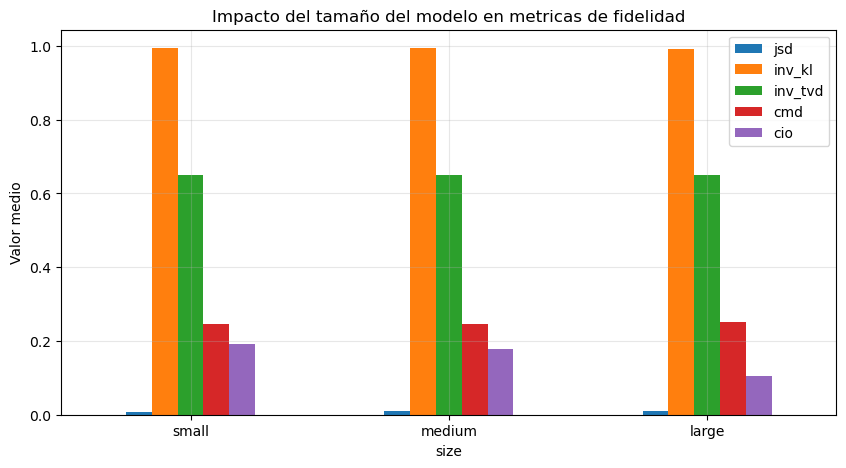

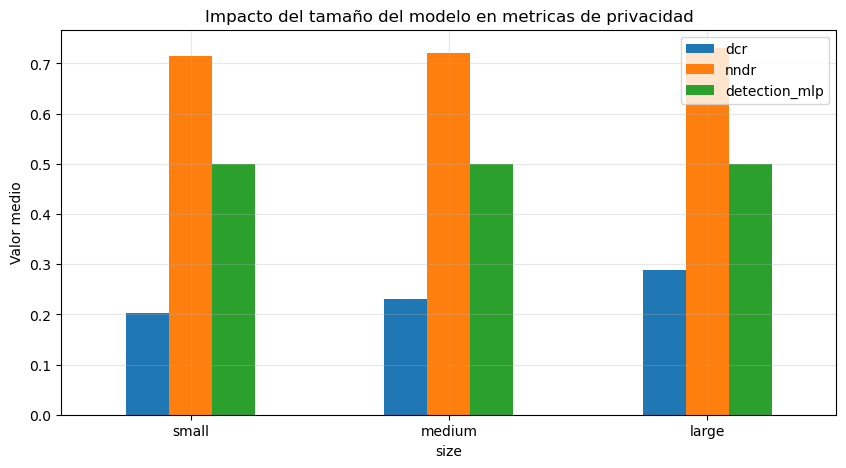

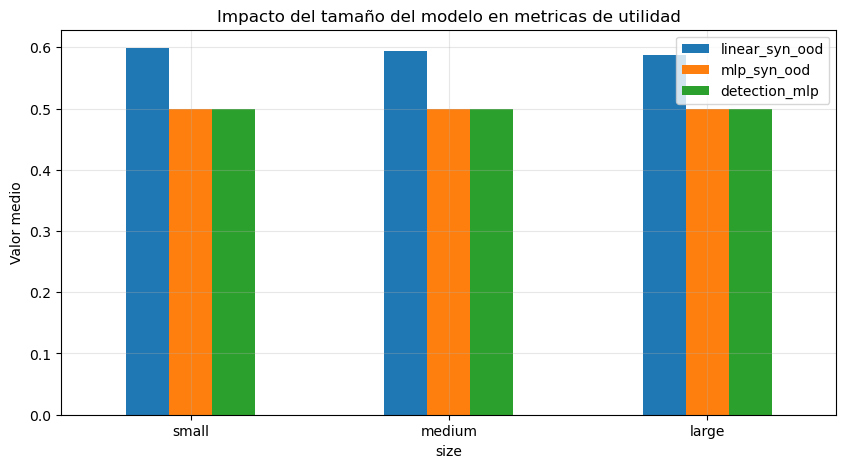

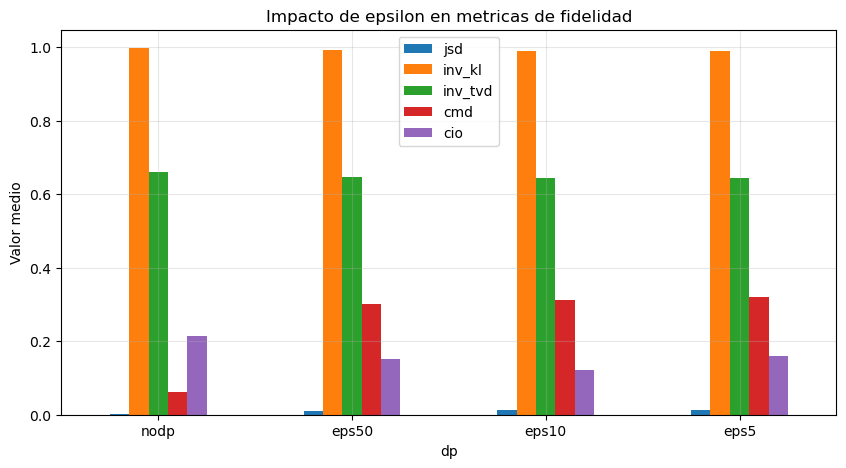

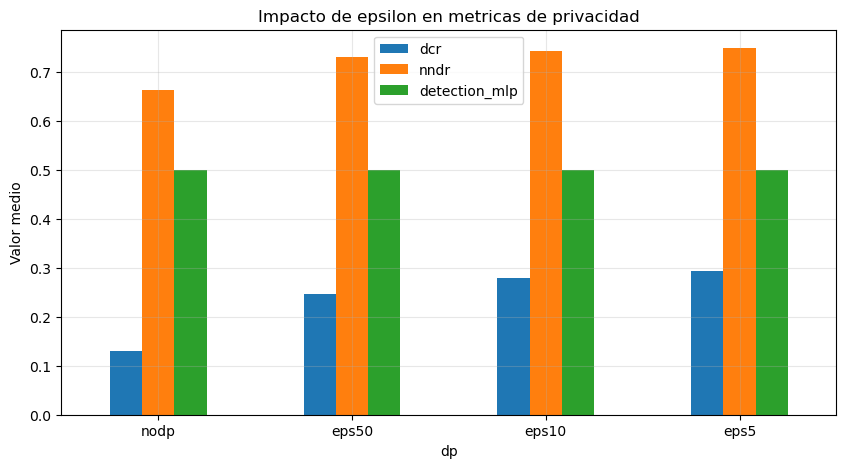

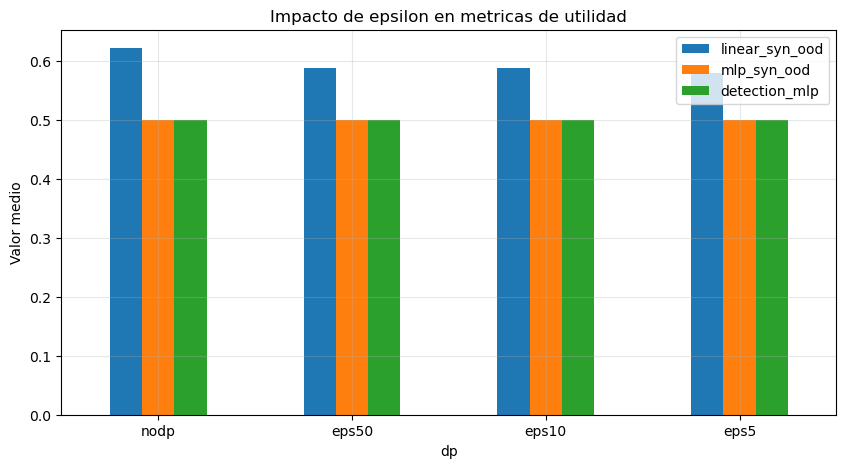

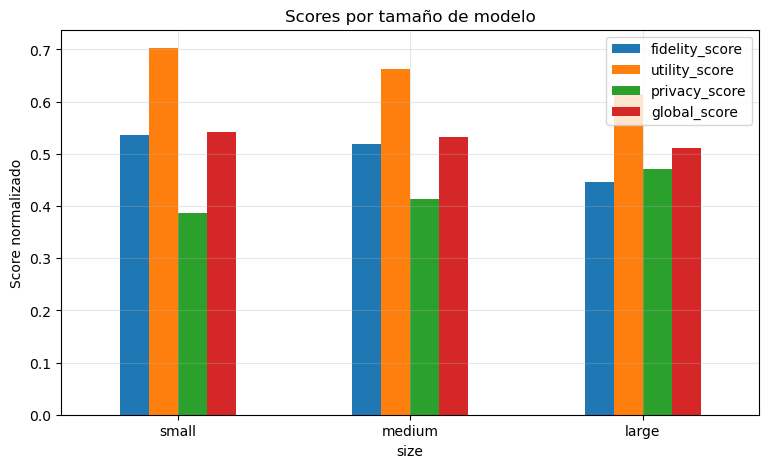

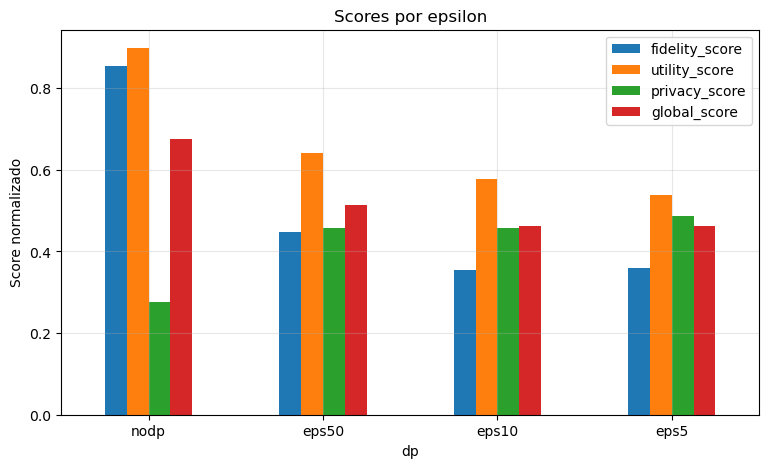

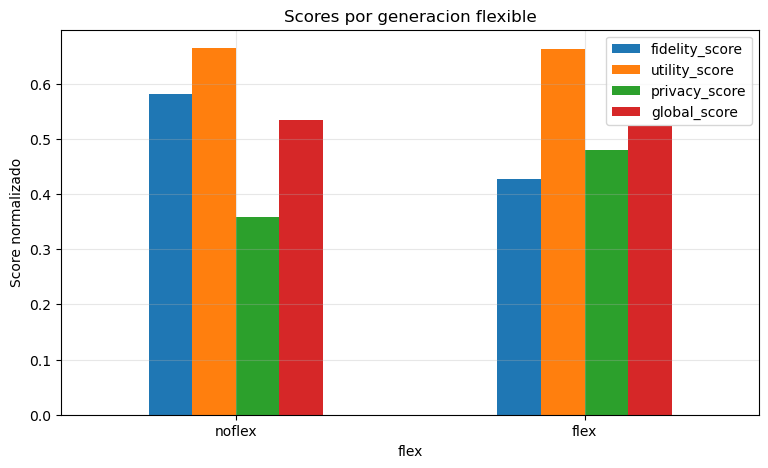

In [11]:
metrics_fidelity = ["jsd", "inv_kl", "inv_tvd", "cmd", "cio"]
metrics_privacy = ["dcr", "nndr", "detection_mlp"]
metrics_privacy_full = ["dcr", "nndr", "k_anonymity", "emr_proxy", "detection_mlp"]
metrics_utility = ["linear_syn_ood", "mlp_syn_ood", "detection_mlp"]

plot_metric_family_by_size(df, metrics_fidelity, "Impacto del tamaño del modelo en metricas de fidelidad")
plot_metric_family_by_size(df, metrics_privacy, "Impacto del tamaño del modelo en metricas de privacidad")
plot_metric_family_by_size(df, metrics_utility, "Impacto del tamaño del modelo en metricas de utilidad")

plot_metric_family_by_dp(df, metrics_fidelity, "Impacto de epsilon en metricas de fidelidad")
plot_metric_family_by_dp(df, metrics_privacy, "Impacto de epsilon en metricas de privacidad")
plot_metric_family_by_dp(df, metrics_utility, "Impacto de epsilon en metricas de utilidad")

plot_score_overview(df)


## 11. Analisis metrica a metrica con tablas



Tabla - tamaño


size,jsd,interpretacion
small,0.008288,Bueno
medium,0.009083,Bueno
large,0.009863,Bueno



Tabla - epsilon


dp,jsd,interpretacion
nodp,0.002196,Bueno
eps50,0.009987,Bueno
eps10,0.011847,Bueno
eps5,0.012020,Bueno



Tabla - gen flex


flex,jsd,interpretacion
noflex,0.007511,Bueno
flex,0.010514,Bueno


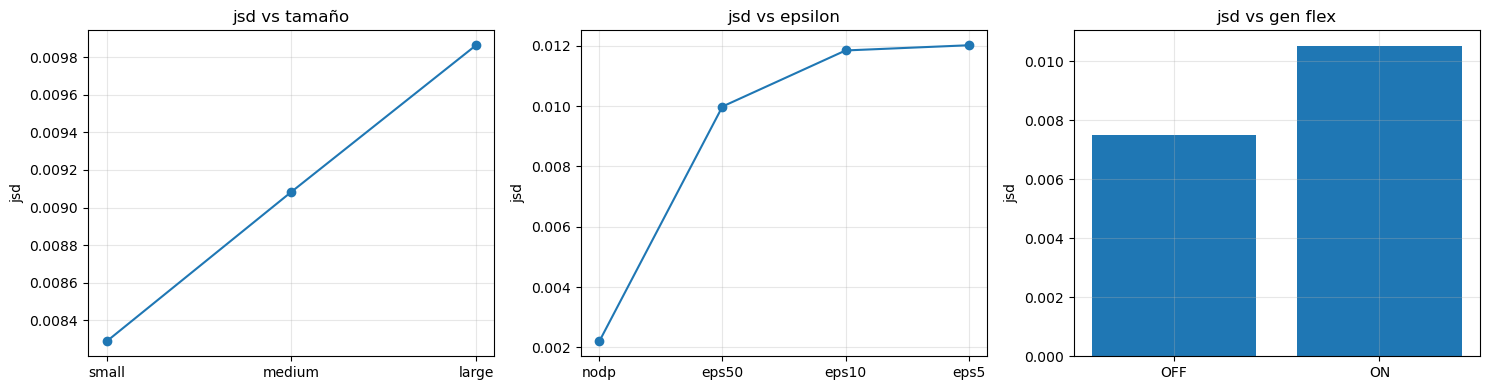


Tabla - tamaño


size,inv_kl,interpretacion
small,0.993949,Bueno
medium,0.993664,Bueno
large,0.992066,Bueno



Tabla - epsilon


dp,inv_kl,interpretacion
nodp,0.998137,Bueno
eps50,0.993856,Bueno
eps10,0.991266,Bueno
eps5,0.989960,Bueno



Tabla - gen flex


flex,inv_kl,interpretacion
noflex,0.996489,Bueno
flex,0.990120,Bueno


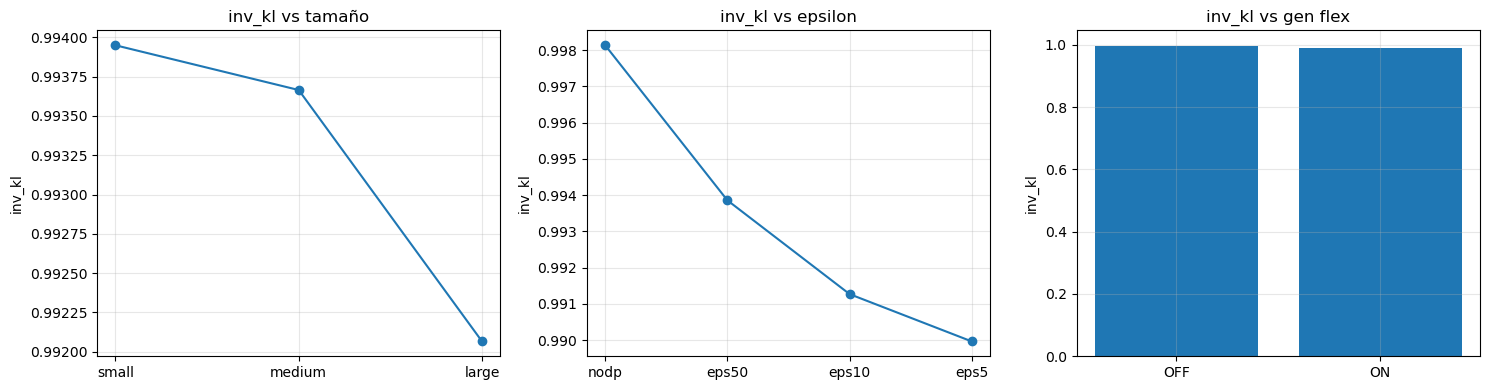


Tabla - tamaño


size,inv_tvd,interpretacion
small,0.650003,Malo
medium,0.650290,Malo
large,0.648524,Malo



Tabla - epsilon


dp,inv_tvd,interpretacion
nodp,0.660740,Malo
eps50,0.647967,Malo
eps10,0.644257,Malo
eps5,0.645704,Malo



Tabla - gen flex


flex,inv_tvd,interpretacion
noflex,0.654510,Malo
flex,0.644824,Malo


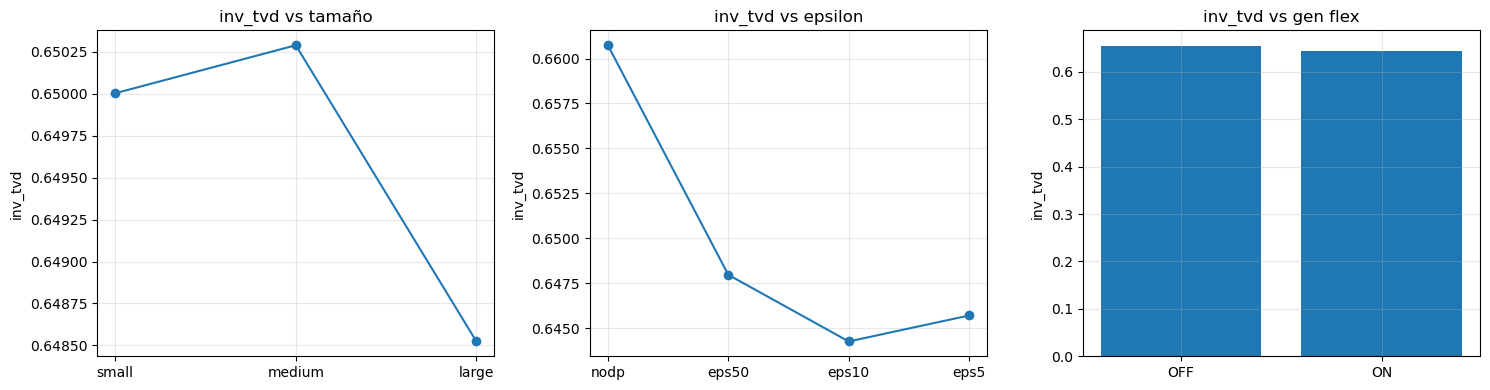


Tabla - tamaño


size,cmd,interpretacion
small,0.246585,Medio
medium,0.246546,Medio
large,0.252238,Medio



Tabla - epsilon


dp,cmd,interpretacion
nodp,0.061308,Bueno
eps50,0.300086,Medio
eps10,0.312254,Medio
eps5,0.319235,Medio



Tabla - gen flex


flex,cmd,interpretacion
noflex,0.253491,Medio
flex,0.242950,Medio


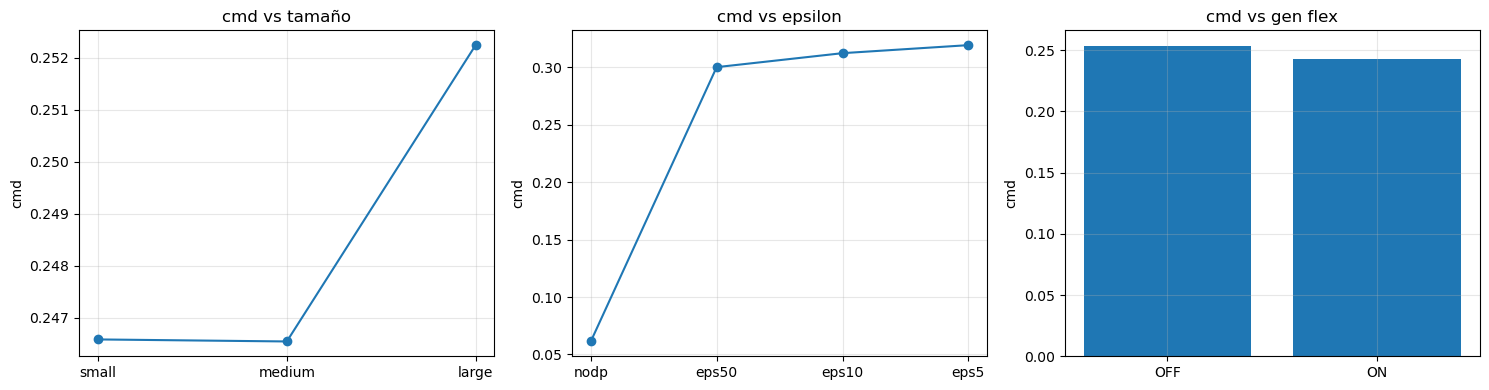


Tabla - tamaño


size,cio,interpretacion
small,0.192725,Bajo
medium,0.177082,Bajo
large,0.105149,Bajo



Tabla - epsilon


dp,cio,interpretacion
nodp,0.213582,Bajo
eps50,0.150599,Bajo
eps10,0.123093,Bajo
eps5,0.160598,Bajo



Tabla - gen flex


flex,cio,interpretacion
noflex,0.155163,Bajo
flex,0.168773,Bajo


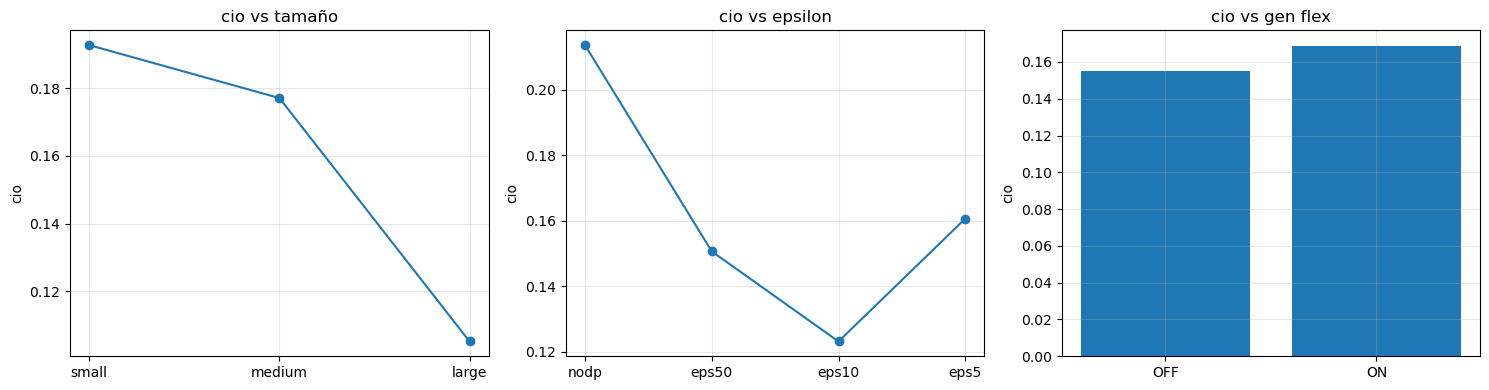


Tabla - tamaño


size,fidelity_score,interpretacion
small,0.536878,Medio
medium,0.518766,Medio
large,0.445111,Medio



Tabla - epsilon


dp,fidelity_score,interpretacion
nodp,0.855554,Alto
eps50,0.448129,Medio
eps10,0.353536,Bajo
eps5,0.359082,Bajo



Tabla - gen flex


flex,fidelity_score,interpretacion
noflex,0.581166,Medio
flex,0.426984,Medio


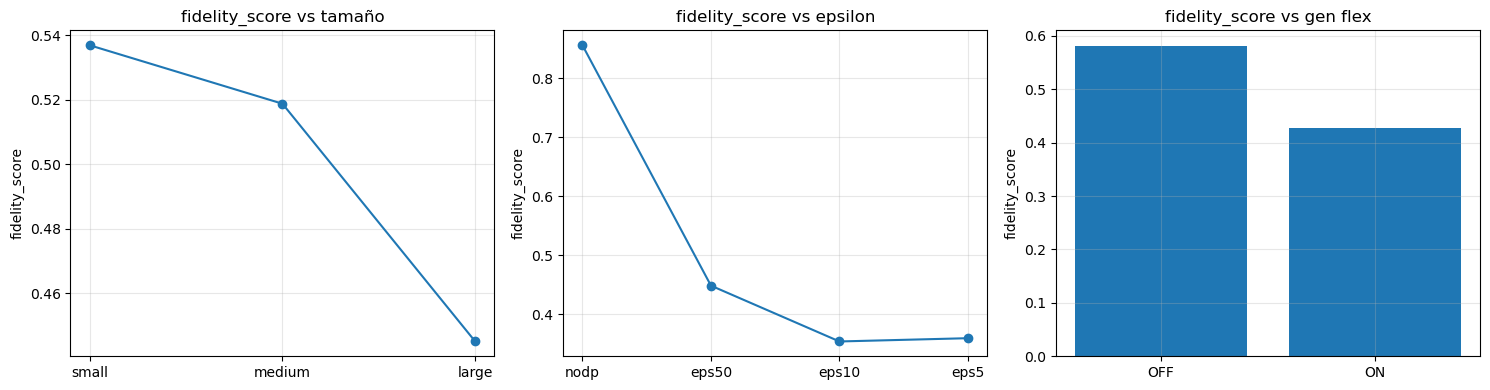


Tabla - tamaño


size,dcr,interpretacion
small,0.202479,Medio
medium,0.231258,Medio
large,0.288459,Medio



Tabla - epsilon


dp,dcr,interpretacion
nodp,0.130039,Bajo
eps50,0.245752,Medio
eps10,0.280196,Medio
eps5,0.292611,Medio



Tabla - gen flex


flex,dcr,interpretacion
noflex,0.210341,Medio
flex,0.263957,Medio


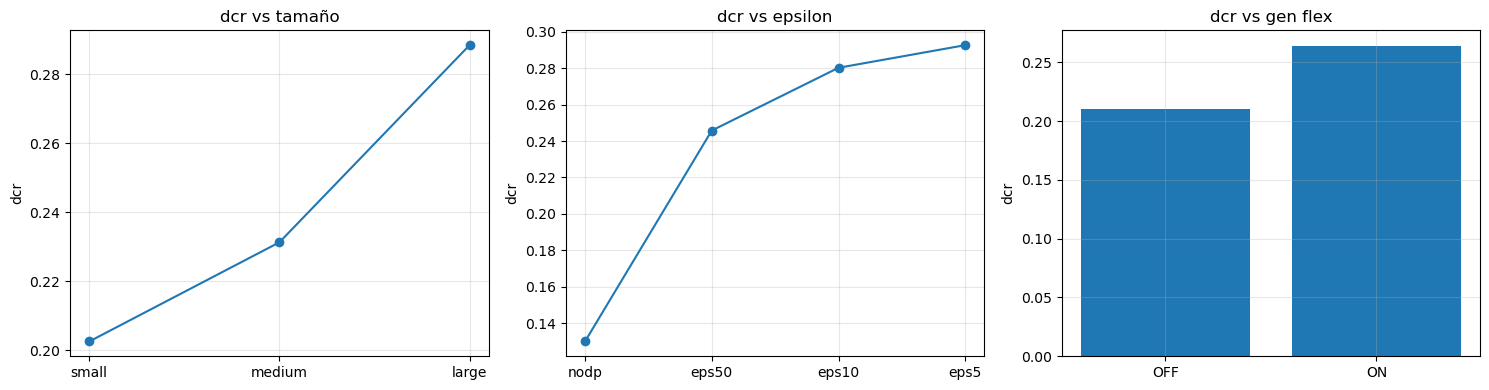


Tabla - tamaño


size,nndr,interpretacion
small,0.714869,Bueno
medium,0.721866,Bueno
large,0.730727,Bueno



Tabla - epsilon


dp,nndr,interpretacion
nodp,0.663410,Medio
eps50,0.731265,Bueno
eps10,0.743776,Bueno
eps5,0.748857,Bueno



Tabla - gen flex


flex,nndr,interpretacion
noflex,0.713942,Bueno
flex,0.729711,Bueno


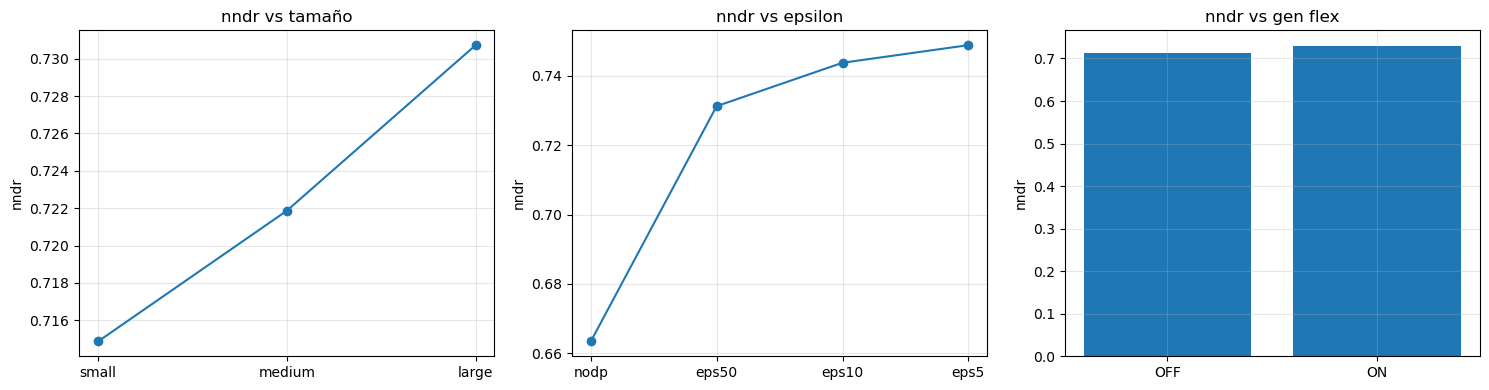


Tabla - tamaño


size,k_anonymity,interpretacion
small,1.000000,No discriminante
medium,1.000000,No discriminante
large,1.000000,No discriminante



Tabla - epsilon


dp,k_anonymity,interpretacion
nodp,1.000000,No discriminante
eps50,1.000000,No discriminante
eps10,1.000000,No discriminante
eps5,1.000000,No discriminante



Tabla - gen flex


flex,k_anonymity,interpretacion
noflex,1.000000,No discriminante
flex,1.000000,No discriminante


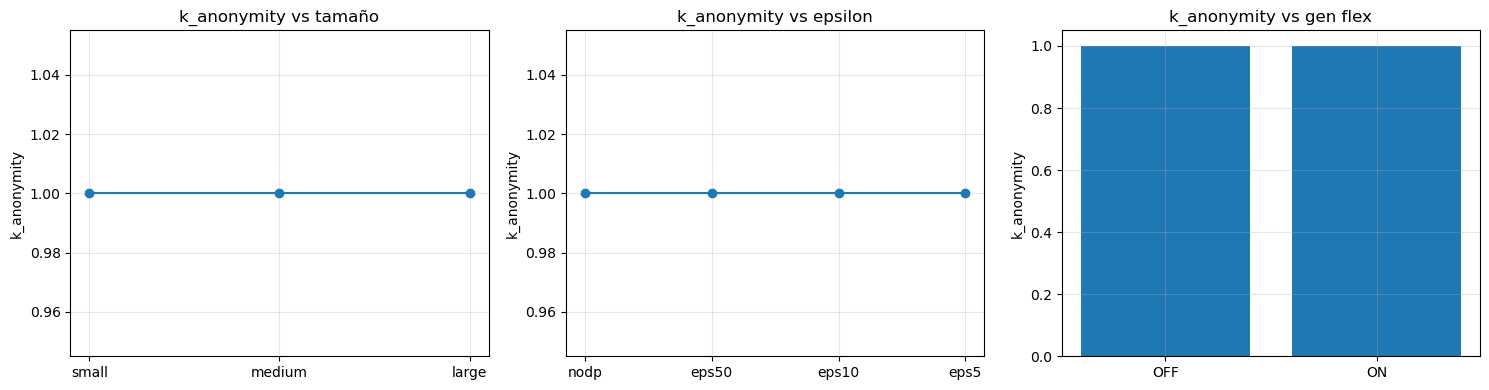


Tabla - tamaño


size,emr_proxy,interpretacion
small,0.000000,Sin copias exactas
medium,0.000000,Sin copias exactas
large,0.000000,Sin copias exactas



Tabla - epsilon


dp,emr_proxy,interpretacion
nodp,0.000000,Sin copias exactas
eps50,0.000000,Sin copias exactas
eps10,0.000000,Sin copias exactas
eps5,0.000000,Sin copias exactas



Tabla - gen flex


flex,emr_proxy,interpretacion
noflex,0.000000,Sin copias exactas
flex,0.000000,Sin copias exactas


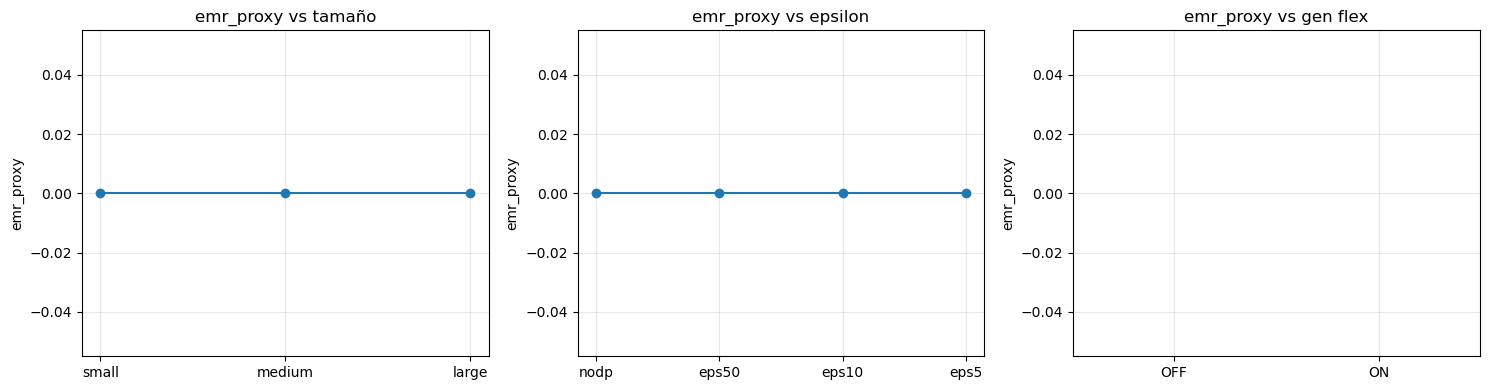


Tabla - tamaño


size,detection_mlp,interpretacion
small,0.499880,Bueno
medium,0.499874,Bueno
large,0.499867,Bueno



Tabla - epsilon


dp,detection_mlp,interpretacion
nodp,0.499912,Bueno
eps50,0.499877,Bueno
eps10,0.499853,Bueno
eps5,0.499855,Bueno



Tabla - gen flex


flex,detection_mlp,interpretacion
noflex,0.499867,Bueno
flex,0.499881,Bueno


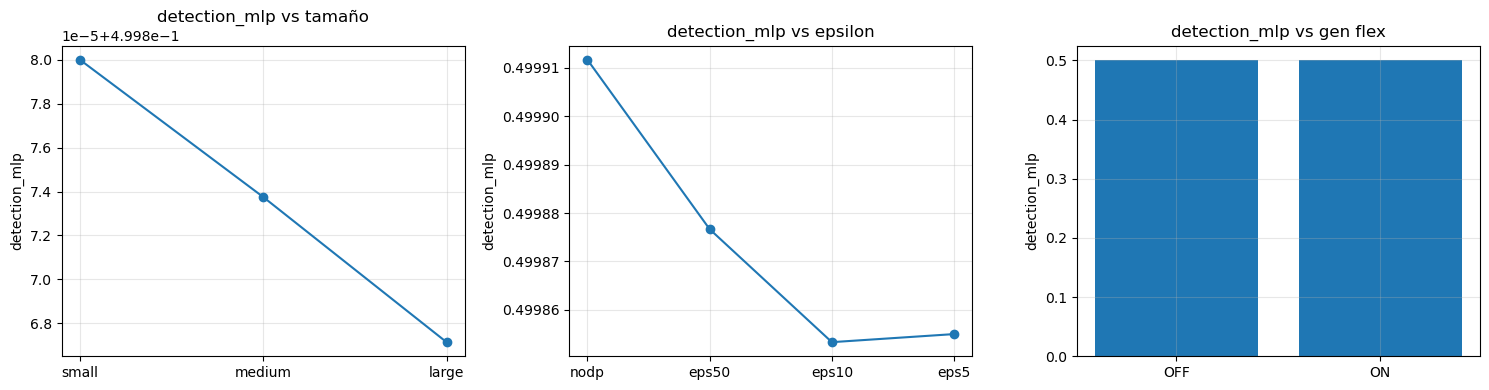


Tabla - tamaño


size,privacy_score,interpretacion
small,0.385534,Bajo
medium,0.412966,Medio
large,0.470240,Medio



Tabla - epsilon


dp,privacy_score,interpretacion
nodp,0.275758,Bajo
eps50,0.456492,Medio
eps10,0.458647,Medio
eps5,0.486639,Medio



Tabla - gen flex


flex,privacy_score,interpretacion
noflex,0.358514,Bajo
flex,0.480254,Medio


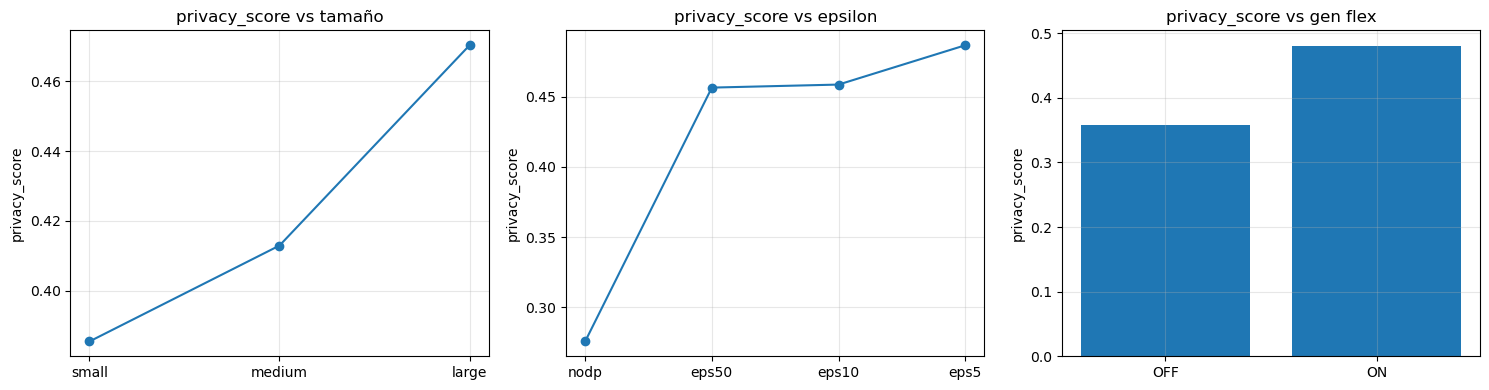


Tabla - tamaño


size,linear_syn_ood,interpretacion
small,0.598709,Medio
medium,0.593823,Medio
large,0.587902,Medio



Tabla - epsilon


dp,linear_syn_ood,interpretacion
nodp,0.621463,Medio
eps50,0.588020,Medio
eps10,0.587458,Medio
eps5,0.578773,Medio



Tabla - gen flex


flex,linear_syn_ood,interpretacion
noflex,0.597545,Medio
flex,0.590312,Medio


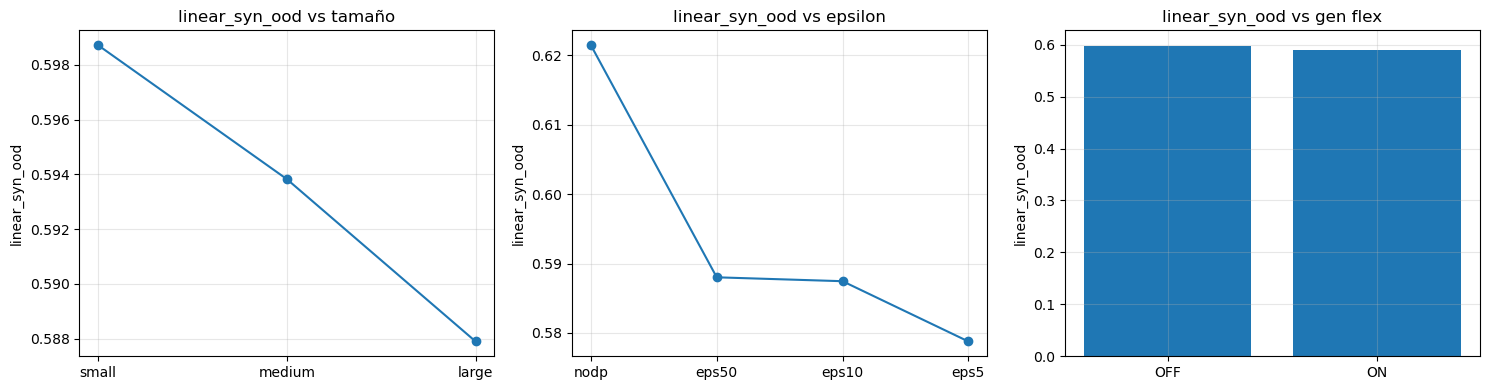


Tabla - tamaño


size,mlp_syn_ood,interpretacion
small,0.500000,Bajo
medium,0.500000,Bajo
large,0.500000,Bajo



Tabla - epsilon


dp,mlp_syn_ood,interpretacion
nodp,0.500000,Bajo
eps50,0.500000,Bajo
eps10,0.500000,Bajo
eps5,0.500000,Bajo



Tabla - gen flex


flex,mlp_syn_ood,interpretacion
noflex,0.500000,Bajo
flex,0.500000,Bajo


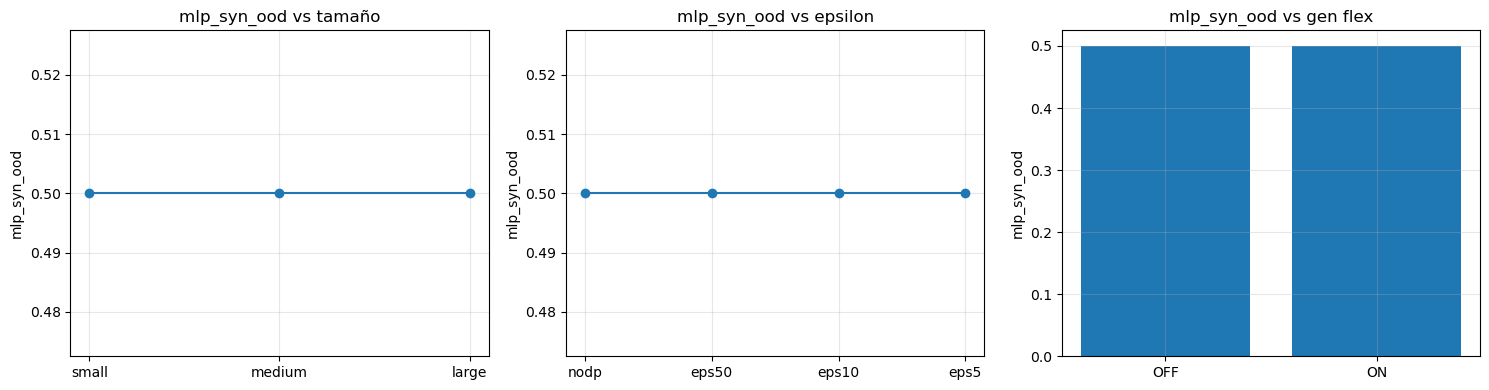


Tabla - tamaño


size,detection_mlp,interpretacion
small,0.499880,Bueno
medium,0.499874,Bueno
large,0.499867,Bueno



Tabla - epsilon


dp,detection_mlp,interpretacion
nodp,0.499912,Bueno
eps50,0.499877,Bueno
eps10,0.499853,Bueno
eps5,0.499855,Bueno



Tabla - gen flex


flex,detection_mlp,interpretacion
noflex,0.499867,Bueno
flex,0.499881,Bueno


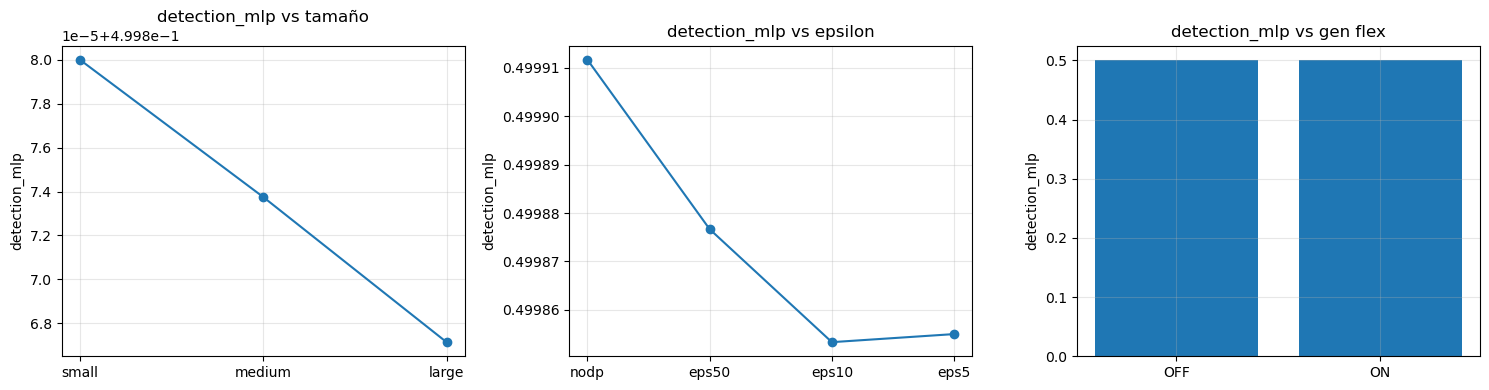


Tabla - tamaño


size,utility_score,interpretacion
small,0.702515,Alto
medium,0.661860,Medio
large,0.615069,Medio



Tabla - epsilon


dp,utility_score,interpretacion
nodp,0.898419,Alto
eps50,0.640081,Medio
eps10,0.577421,Medio
eps5,0.537911,Medio



Tabla - gen flex


flex,utility_score,interpretacion
noflex,0.664595,Medio
flex,0.662321,Medio


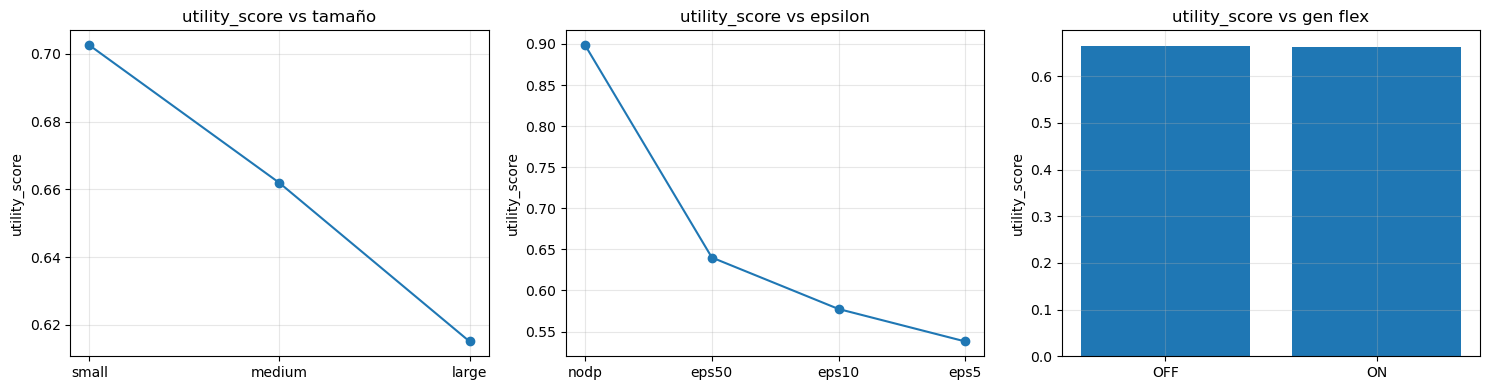

In [12]:
for metric in metrics_fidelity + ["fidelity_score"]:
    plot_metric_with_tables(df, metric)

for metric in metrics_privacy_full + ["privacy_score"]:
    plot_metric_with_tables(df, metric)

for metric in metrics_utility + ["utility_score"]:
    plot_metric_with_tables(df, metric)


## 12. Analisis de utilidad: GT, Syn ID, Syn OOD


,job_name_resolved,size,dp,flex,linear_gt,linear_syn_id,linear_syn_ood,mlp_gt,mlp_syn_id,mlp_syn_ood,linear_gap_gt_syn_ood,mlp_gap_gt_syn_ood,linear_overfit_gap,mlp_overfit_gap,complexity_gap_mlp_minus_linear
4,eval_single_large_eps5_flex,large,eps5,flex,0.622635,0.561904,0.561080,0.499701,0.500000,0.5,0.061555,-0.000299,0.000824,0.000000,-0.061080
5,eval_single_large_eps10_noflex,large,eps10,noflex,0.618033,0.574364,0.579504,0.500000,0.500000,0.5,0.038528,0.000000,-0.005140,0.000000,-0.079504
6,eval_single_large_eps10_flex,large,eps10,flex,0.622839,0.570474,0.576496,0.500386,0.500000,0.5,0.046343,0.000386,-0.006023,0.000000,-0.076496
7,eval_single_large_eps50_noflex,large,eps50,noflex,0.616956,0.575875,0.581070,0.500000,0.500000,0.5,0.035886,0.000000,-0.005195,0.000000,-0.081070
8,eval_single_large_eps50_flex,large,eps50,flex,0.620374,0.571293,0.574823,0.500000,0.500000,0.5,0.045550,0.000000,-0.003530,0.000000,-0.074823
9,eval_single_large_nodp_noflex,large,nodp,noflex,0.617546,0.608252,0.615138,0.499956,0.500000,0.5,0.002408,-0.000044,-0.006886,0.000000,-0.115138
10,eval_single_large_nodp_flex,large,nodp,flex,0.617377,0.619283,0.627202,0.500285,0.500000,0.5,-0.009825,0.000285,-0.007919,0.000000,-0.127202
11,eval_single_medium_eps5_noflex,medium,eps5,noflex,0.619122,0.581644,0.586625,0.501285,0.500000,0.5,0.032496,0.001285,-0.004982,0.000000,-0.086625
12,eval_single_medium_eps5_flex,medium,eps5,flex,0.617966,0.561098,0.569633,0.500181,0.500000,0.5,0.048332,0.000181,-0.008536,0.000000,-0.069633
13,eval_single_medium_eps10_noflex,medium,eps10,noflex,0.618361,0.581129,0.586589,0.500000,0.500000,0.5,0.031772,0.000000,-0.005460,0.000000,-0.086589


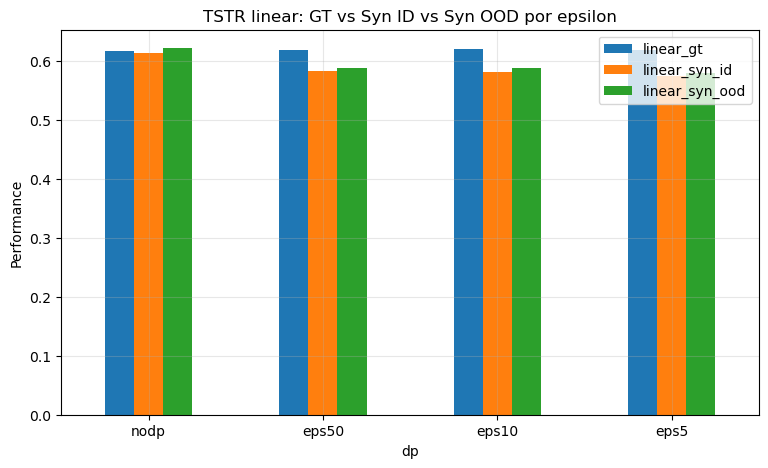

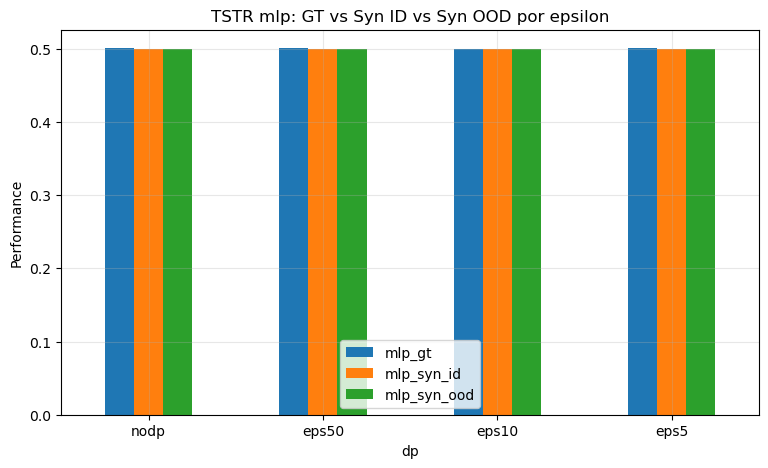

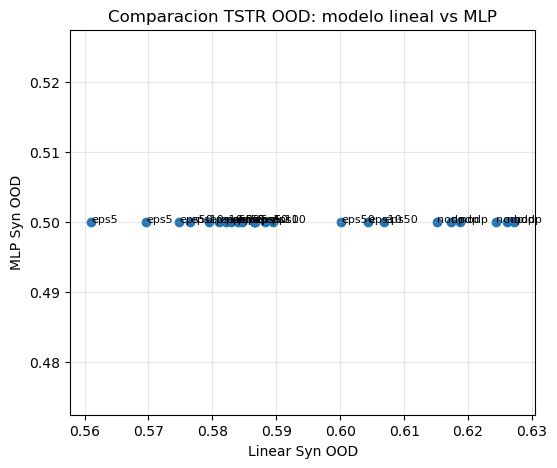

In [13]:
utility_comparison_cols = [
    "linear_gt", "linear_syn_id", "linear_syn_ood",
    "mlp_gt", "mlp_syn_id", "mlp_syn_ood",
    "linear_gap_gt_syn_ood", "mlp_gap_gt_syn_ood",
    "linear_overfit_gap", "mlp_overfit_gap",
    "complexity_gap_mlp_minus_linear",
]

display(df[["job_name_resolved", "size", "dp", "flex"] + utility_comparison_cols])

# GT vs Syn OOD por epsilon
for model_prefix in ["linear", "mlp"]:
    cols = [f"{model_prefix}_gt", f"{model_prefix}_syn_id", f"{model_prefix}_syn_ood"]
    df.groupby("dp", observed=False)[cols].mean().reindex(ORDER_DP).plot(kind="bar", figsize=(9, 5))
    plt.title(f"TSTR {model_prefix}: GT vs Syn ID vs Syn OOD por epsilon")
    plt.ylabel("Performance")
    plt.xticks(rotation=0)
    plt.grid(alpha=0.3)
    plt.show()

# Comparacion linear vs MLP OOD
plt.figure(figsize=(6, 5))
plt.scatter(df["linear_syn_ood"], df["mlp_syn_ood"])
for _, row in df.iterrows():
    plt.text(row["linear_syn_ood"], row["mlp_syn_ood"], str(row["dp"]), fontsize=8)
plt.xlabel("Linear Syn OOD")
plt.ylabel("MLP Syn OOD")
plt.title("Comparacion TSTR OOD: modelo lineal vs MLP")
plt.grid(alpha=0.3)
plt.show()


## 13. Analisis de epsilons bajos

Este bloque asume que las 3 evaluaciones mas recientes son, por orden temporal ascendente:
`eps01`, `eps05`, `eps1`. Ajustar `LOW_EPS_LABELS` si no corresponde.


In [14]:
LOW_EPS_LABELS = ["eps01", "eps05", "eps1"]


def build_low_eps_df(eval_root: Path, eps_labels=LOW_EPS_LABELS) -> pd.DataFrame:
    cards = []

    for eval_dir in eval_root.iterdir():
        if not eval_dir.is_dir() or not eval_dir.name.startswith("evaluation_"):
            continue

        card_path = eval_dir / "eval_card.json"
        report_path = eval_dir / "eval_report.csv"
        if not card_path.exists() or not report_path.exists():
            continue

        card = load_json(card_path)
        if card.get("status") != "completed":
            continue

        cards.append({
            "evaluation_id": card.get("evaluation_id"),
            "evaluation_path": str(eval_dir),
            "timestamp": card.get("timestamp"),
            "model_id": card.get("model_id"),
            "simulation_id": card.get("simulation_id"),
        })

    df_cards = pd.DataFrame(cards).sort_values("timestamp", ascending=False).reset_index(drop=True)
    df_low_cards = df_cards.head(len(eps_labels)).copy()

    rows = []
    for eps_label, (_, row) in zip(eps_labels, df_low_cards.sort_values("timestamp").iterrows()):
        eval_dir = Path(row["evaluation_path"])
        metrics = extract_metrics(eval_dir / "eval_report.csv")
        rows.append({
            "evaluation_id": row["evaluation_id"],
            "evaluation_path": row["evaluation_path"],
            "timestamp": row["timestamp"],
            "simulation_id": row["simulation_id"],
            "model_id": row["model_id"],
            "pipeline_id": None,
            "job_name": f"eval_single_medium_{eps_label}_noflex",
            "job_name_resolved": f"eval_single_medium_{eps_label}_noflex",
            "size": "medium",
            "dp": eps_label,
            "flex": "noflex",
            **metrics,
        })

    df_low = pd.DataFrame(rows)
    df_low["size"] = pd.Categorical(df_low["size"], categories=ORDER_SIZE, ordered=True)
    df_low["dp"] = pd.Categorical(df_low["dp"], categories=ORDER_DP_EXTENDED, ordered=True)
    df_low["flex"] = pd.Categorical(df_low["flex"], categories=ORDER_FLEX, ordered=True)
    return add_scores(df_low)


df_low_eps = build_low_eps_df(EVAL_ROOT)

display(df_low_eps[[
    "job_name_resolved", "size", "dp", "flex",
    "jsd", "inv_tvd", "cmd", "cio",
    "linear_syn_ood", "mlp_syn_ood",
    "dcr", "nndr", "k_anonymity", "emr_proxy", "detection_mlp",
    "fidelity_score", "utility_score", "privacy_score", "global_score"
]])


,job_name_resolved,size,dp,flex,jsd,inv_tvd,cmd,cio,linear_syn_ood,mlp_syn_ood,dcr,nndr,k_anonymity,emr_proxy,detection_mlp,fidelity_score,utility_score,privacy_score,global_score
0,eval_single_medium_eps01_noflex,medium,eps01,noflex,0.018092,0.637743,0.370764,0.0,0.566025,0.5,0.556634,0.812657,1.0,0.0,0.49981,1.000000,0.333333,0.000000,0.444444
1,eval_single_medium_eps05_noflex,medium,eps05,noflex,0.019911,0.622117,0.380038,0.0,0.598234,0.5,0.635736,0.822415,1.0,0.0,0.49989,0.672345,0.962963,0.550711,0.728673
2,eval_single_medium_eps1_noflex,medium,eps1,noflex,0.023533,0.591064,0.386610,0.0,0.569823,0.5,0.770389,0.837475,1.0,0.0,0.49990,0.200000,0.705966,1.000000,0.635322


,dp,fidelity_score,utility_score,privacy_score,global_score,jsd,inv_tvd,cmd,cio,linear_syn_ood,mlp_syn_ood,dcr,nndr,detection_mlp
13,nodp,0.762141,0.898609,0.311931,0.657560,0.003187,0.659209,0.074927,0.120449,0.617262,0.5,0.130673,0.669309,0.49992
11,eps50,0.505274,0.709634,0.423118,0.546009,0.009049,0.651665,0.317692,0.158885,0.600121,0.5,0.217551,0.724684,0.49988
9,eps10,0.440246,0.590136,0.394904,0.475095,0.009290,0.652601,0.307359,0.000000,0.586589,0.5,0.230126,0.729433,0.49986
7,eps5,0.418213,0.462113,0.307671,0.395999,0.010300,0.652611,0.310962,0.000000,0.586625,0.5,0.251581,0.738206,0.49981
26,eps1,0.200000,0.705966,1.000000,0.635322,0.023533,0.591064,0.386610,0.000000,0.569823,0.5,0.770389,0.837475,0.49990
25,eps05,0.672345,0.962963,0.550711,0.728673,0.019911,0.622117,0.380038,0.000000,0.598234,0.5,0.635736,0.822415,0.49989
24,eps01,1.000000,0.333333,0.000000,0.444444,0.018092,0.637743,0.370764,0.000000,0.566025,0.5,0.556634,0.812657,0.49981


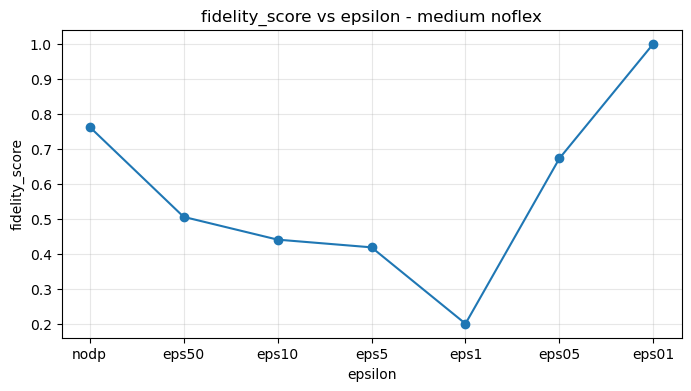

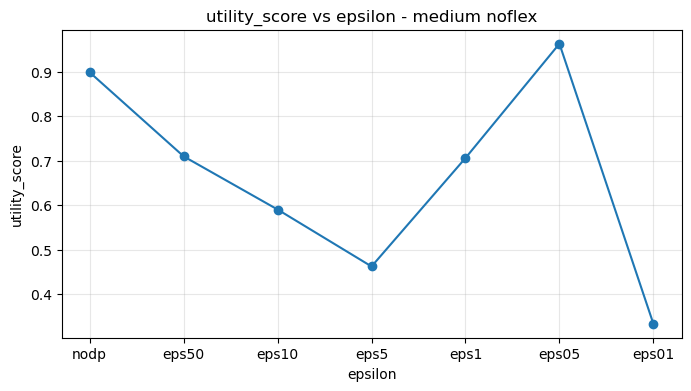

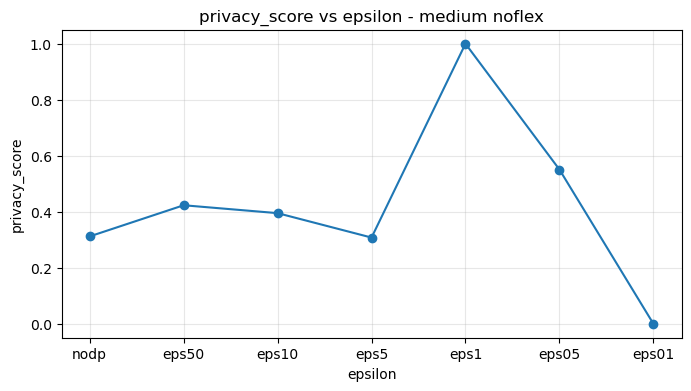

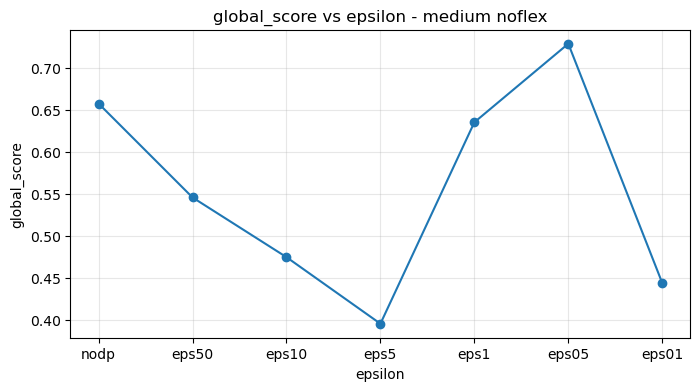

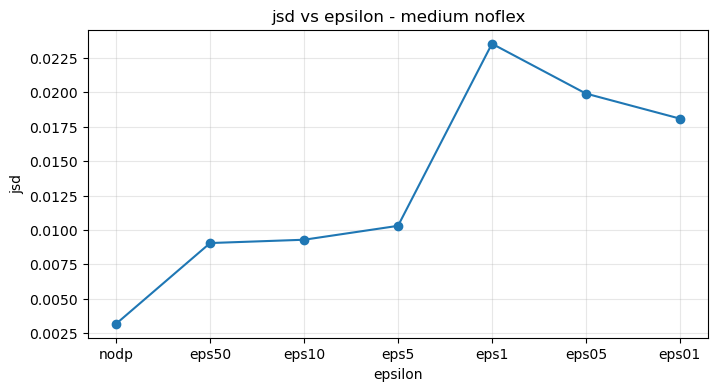

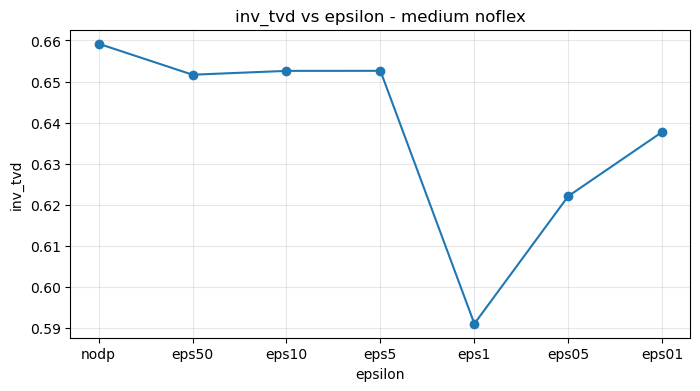

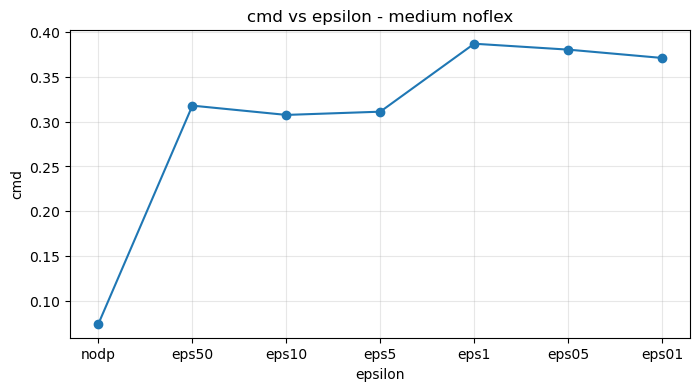

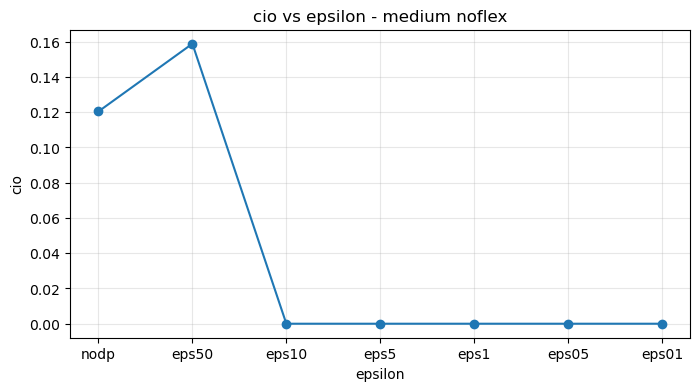

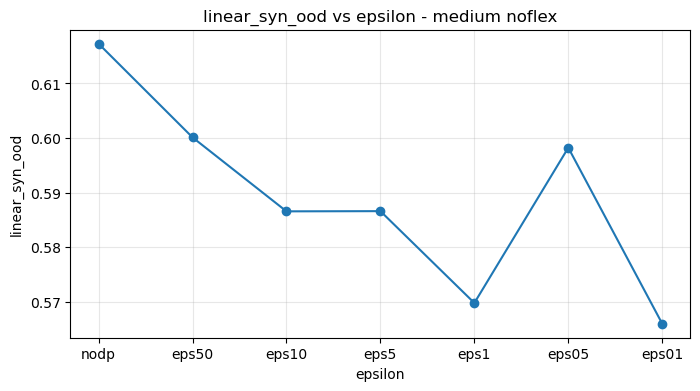

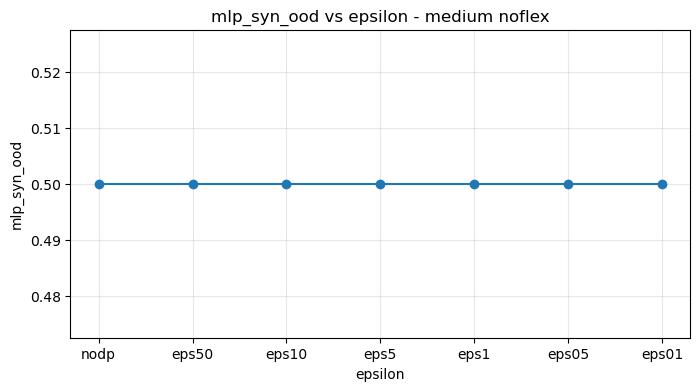

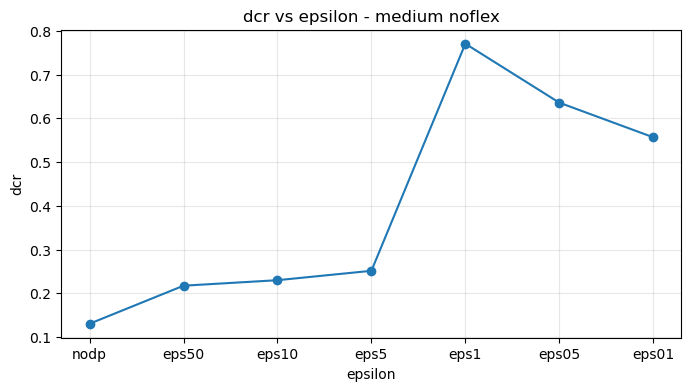

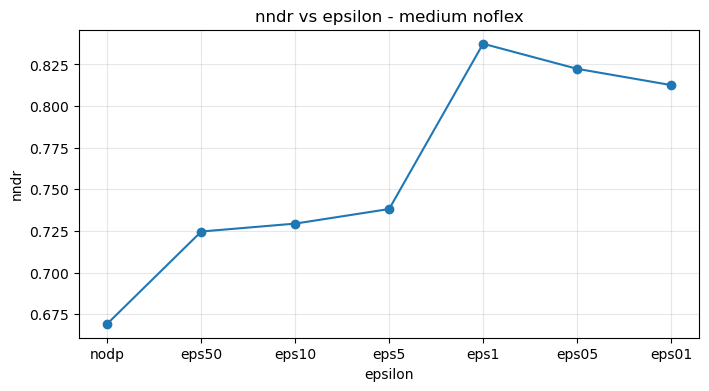

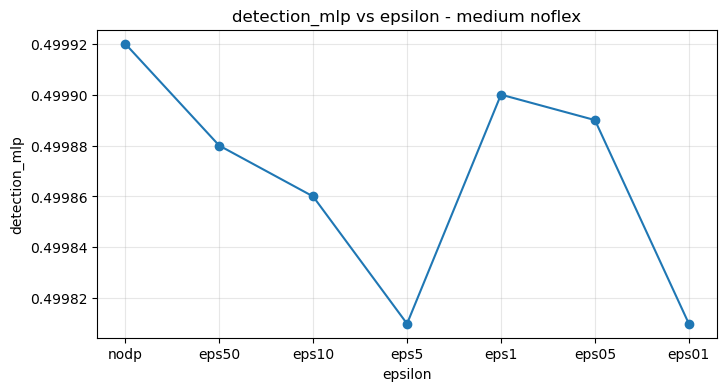

In [15]:
df_compare = pd.concat([df, df_low_eps], ignore_index=True)
df_compare["dp"] = pd.Categorical(df_compare["dp"], categories=ORDER_DP_EXTENDED, ordered=True)

df_medium_noflex = (
    df_compare[(df_compare["size"] == "medium") & (df_compare["flex"] == "noflex")]
    .sort_values("dp")
)

display(df_medium_noflex[[
    "dp", "fidelity_score", "utility_score", "privacy_score", "global_score",
    "jsd", "inv_tvd", "cmd", "cio",
    "linear_syn_ood", "mlp_syn_ood",
    "dcr", "nndr", "detection_mlp"
]])

metrics_low_eps = [
    "fidelity_score", "utility_score", "privacy_score", "global_score",
    "jsd", "inv_tvd", "cmd", "cio",
    "linear_syn_ood", "mlp_syn_ood", "dcr", "nndr", "detection_mlp",
]

for metric in metrics_low_eps:
    plt.figure(figsize=(8, 4))
    plt.plot(df_medium_noflex["dp"].astype(str), df_medium_noflex[metric], marker="o")
    plt.title(f"{metric} vs epsilon - medium noflex")
    plt.xlabel("epsilon")
    plt.ylabel(metric)
    plt.grid(alpha=0.3)
    plt.show()


## 14. Diagnostico CIO

Objetivo: comprobar si el bajo CIO se debe a diferencias relevantes o a intervalos muy estrechos por N grande.
En este proyecto se observo que CIO solo se calcula para `gender` y varios estadisticos.


Columnas evaluadas en CIO: ['gender']
Estadisticos evaluados en CIO: ['KurtosisStatistic', 'MeanStatistic', 'MedianStatistic', 'ModeStatistic', 'QuantileStatistic', 'SkewnessStatistic', 'VarianceStatistic']


,job_name_resolved,size,dp,flex,column,stat,real_value,synthetic_value,abs_diff,avg_ci_width,diff_vs_ci_width,overlap
0,eval_single_large_eps5_flex,large,eps5,flex,gender,MeanStatistic,0.560180,0.505780,0.054400,0.008260,6.585637,0.000000
1,eval_single_large_eps5_flex,large,eps5,flex,gender,MedianStatistic,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
2,eval_single_large_eps5_flex,large,eps5,flex,gender,ModeStatistic,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
3,eval_single_large_eps5_flex,large,eps5,flex,gender,VarianceStatistic,0.246382,0.249972,0.003589,0.000529,6.784041,0.000000
4,eval_single_large_eps5_flex,large,eps5,flex,gender,SkewnessStatistic,-0.242483,-0.023122,0.219362,0.033573,6.533916,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
163,eval_single_small_eps5_noflex,small,eps5,noflex,gender,ModeStatistic,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
164,eval_single_small_eps5_noflex,small,eps5,noflex,gender,VarianceStatistic,0.246382,0.246851,0.000469,0.000968,0.483941,0.350142
165,eval_single_small_eps5_noflex,small,eps5,noflex,gender,SkewnessStatistic,-0.242483,-0.226071,0.016413,0.033905,0.484073,0.330824
166,eval_single_small_eps5_noflex,small,eps5,noflex,gender,KurtosisStatistic,-1.941202,-1.948892,0.007690,0.015655,0.491219,0.336058


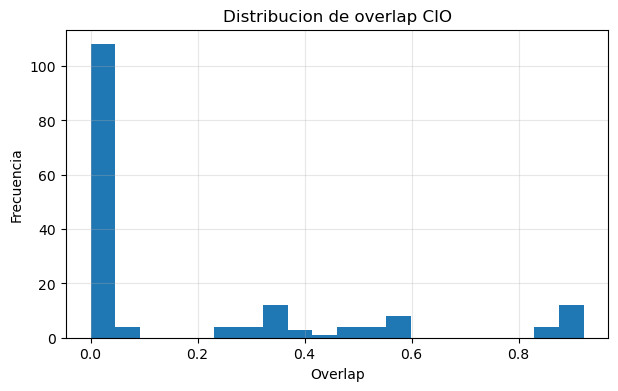

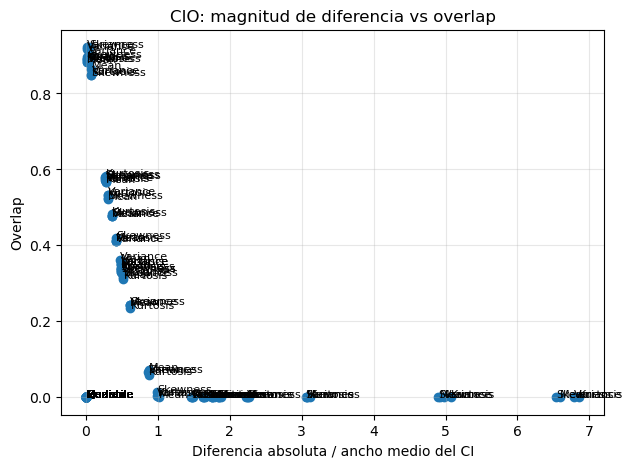

,column,stat,real_value,synthetic_value,abs_diff,avg_ci_width,diff_vs_ci_width,overlap
0,gender,KurtosisStatistic,-1.941202,-1.952761,0.015818,0.015119,1.265754,0.321807
1,gender,MeanStatistic,0.560180,0.551997,0.010240,0.008250,1.241595,0.322604
2,gender,MedianStatistic,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
3,gender,ModeStatistic,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
4,gender,QuantileStatistic,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
5,gender,SkewnessStatistic,-0.242483,-0.209344,0.041563,0.033811,1.233438,0.323809
6,gender,VarianceStatistic,0.246382,0.247092,0.000967,0.000930,1.248070,0.327523


In [16]:
def extract_cio_details(eval_path: str | Path) -> pd.DataFrame | None:
    eval_path = Path(eval_path)
    cio_path = eval_path / "confidence_interval_overlap_report.json"
    if not cio_path.exists():
        return None

    data = load_json(cio_path)
    rows = []

    for key, info in data.items():
        if not isinstance(info, dict):
            continue

        # Ejemplo key: dataset_prueba_tecnica_v2_gender_MeanStatistic
        stat_match = re.search(r"_([^_]+Statistic)$", key)
        stat = stat_match.group(1) if stat_match else None

        column = key
        if stat:
            prefix = key[: -(len(stat) + 1)]
            column = prefix.split("_")[-1]

        rows.append({
            "raw_key": key,
            "column": column,
            "stat": stat,
            "overlap": info.get("overlap"),
            "real_value": info.get("real_value"),
            "synthetic_value": info.get("synthetic_value"),
            "real_ci_lower": info.get("real_ci_lower"),
            "real_ci_upper": info.get("real_ci_upper"),
            "synthetic_ci_lower": info.get("synthetic_ci_lower"),
            "synthetic_ci_upper": info.get("synthetic_ci_upper"),
        })

    return pd.DataFrame(rows)


def analyze_cio(df_cio: pd.DataFrame) -> pd.DataFrame:
    df_cio = df_cio.copy()
    df_cio["abs_diff"] = (df_cio["real_value"] - df_cio["synthetic_value"]).abs()
    df_cio["real_ci_width"] = df_cio["real_ci_upper"] - df_cio["real_ci_lower"]
    df_cio["synthetic_ci_width"] = df_cio["synthetic_ci_upper"] - df_cio["synthetic_ci_lower"]
    df_cio["avg_ci_width"] = df_cio[["real_ci_width", "synthetic_ci_width"]].mean(axis=1)
    df_cio["diff_vs_ci_width"] = df_cio["abs_diff"] / (df_cio["avg_ci_width"] + 1e-9)
    return df_cio


def build_cio_all(df_evals: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, row in df_evals.iterrows():
        details = extract_cio_details(row["evaluation_path"])
        if details is None or details.empty:
            continue
        details = analyze_cio(details)
        details["job_name_resolved"] = row["job_name_resolved"]
        details["size"] = row["size"]
        details["dp"] = row["dp"]
        details["flex"] = row["flex"]
        details["evaluation_id"] = row["evaluation_id"]
        rows.append(details)

    if not rows:
        return pd.DataFrame()
    return pd.concat(rows, ignore_index=True)


def plot_cio_diagnostics(df_cio: pd.DataFrame):
    if df_cio.empty:
        print("No hay detalle CIO para graficar.")
        return

    plt.figure(figsize=(7, 4))
    plt.hist(df_cio["overlap"].dropna(), bins=20)
    plt.title("Distribucion de overlap CIO")
    plt.xlabel("Overlap")
    plt.ylabel("Frecuencia")
    plt.grid(alpha=0.3)
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.scatter(df_cio["diff_vs_ci_width"], df_cio["overlap"])
    for _, row in df_cio.iterrows():
        plt.text(row["diff_vs_ci_width"], row["overlap"], str(row["stat"]).replace("Statistic", ""), fontsize=8)
    plt.xlabel("Diferencia absoluta / ancho medio del CI")
    plt.ylabel("Overlap")
    plt.title("CIO: magnitud de diferencia vs overlap")
    plt.grid(alpha=0.3)
    plt.show()


df_cio_all = build_cio_all(df)

if not df_cio_all.empty:
    print("Columnas evaluadas en CIO:", sorted(df_cio_all["column"].dropna().unique().tolist()))
    print("Estadisticos evaluados en CIO:", sorted(df_cio_all["stat"].dropna().unique().tolist()))
    display(df_cio_all[[
        "job_name_resolved", "size", "dp", "flex", "column", "stat",
        "real_value", "synthetic_value", "abs_diff", "avg_ci_width", "diff_vs_ci_width", "overlap"
    ]])
    plot_cio_diagnostics(df_cio_all)

    cio_summary = df_cio_all.groupby(["column", "stat"], observed=False)[[
        "real_value", "synthetic_value", "abs_diff", "avg_ci_width", "diff_vs_ci_width", "overlap"
    ]].mean().reset_index()
    display(cio_summary)
else:
    print("No se encontro confidence_interval_overlap_report.json en las evaluaciones seleccionadas.")


## 15. Comprobacion de tipos del dataset real


In [17]:
if DATA_PATH.exists():
    df_real = pd.read_csv(DATA_PATH)
    print("Tipos de columnas del dataset real:")
    display(df_real.dtypes)
    print("Columnas numericas:", df_real.select_dtypes(include="number").columns.tolist())
    print("N columnas numericas:", len(df_real.select_dtypes(include="number").columns))
else:
    print("No existe DATA_PATH. Ajusta la variable DATA_PATH al comienzo del script.")


Tipos de columnas del dataset real:


idx                   int64
SUBJECT_ID            int64
GENDER               object
DOB                  object
EXPIRE_FLAG            bool
ADMITTIME            object
DISCHTIME            object
ADMISSION_TYPE       object
INSURANCE            object
MARITAL_STATUS       object
ETHNICITY_GROUPED    object
dtype: object

Columnas numericas: ['idx', 'SUBJECT_ID']
N columnas numericas: 2


## 16. Export de resultados


In [18]:
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "analysis_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df.to_csv(OUTPUT_DIR / "experiments_24_scored.csv", index=False)
ranking.to_csv(OUTPUT_DIR / "ranking_global.csv", index=False)
summary = df.groupby(["size", "dp", "flex"], observed=False)[[
    "fidelity_score", "utility_score", "privacy_score", "global_score",
    "jsd", "inv_kl", "inv_tvd", "cmd", "cio",
    "linear_syn_ood", "mlp_syn_ood", "detection_mlp",
    "dcr", "nndr", "k_anonymity", "emr_proxy",
]].mean().reset_index()
summary.to_csv(OUTPUT_DIR / "summary_results_clean.csv", index=False)

df_low_eps.to_csv(OUTPUT_DIR / "low_epsilon_experiments.csv", index=False)
df_medium_noflex.to_csv(OUTPUT_DIR / "low_epsilon_medium_noflex_analysis.csv", index=False)

if not df_cio_all.empty:
    df_cio_all.to_csv(OUTPUT_DIR / "cio_diagnostics_all.csv", index=False)
    cio_summary.to_csv(OUTPUT_DIR / "cio_diagnostics_summary.csv", index=False)

print("Resultados exportados en:", OUTPUT_DIR)


Resultados exportados en: /home/sagemaker-user/herramienta-datos-sinteticos/notebooks/analysis_outputs


In [ ]:
a